# Monthly Mean Air Temperature Forecasting Using Machine Learning

**Project ID:** PRAICP-1003-AirTempTS  
**Study location:** Changi Climate Station, Singapore  
**Reporting interval:** Monthly  
**Historical dataset coverage:** January 1982–June 2020  

**Project purpose:** Develop, validate, and interpret 12-month-ahead forecasting methods for monthly mean surface air temperature, using leakage-aware chronological evaluation. The final projection is retrospective relative to today, because the dataset ends in June 2020.

## Project Overview and Problem Statement

The project requires a machine learning model capable of forecasting *monthly mean air temperature* for upcoming months. Monthly temperature patterns can influence operational planning, climate monitoring, and resource scheduling. These are potential applications, **not claimed outcomes of this dataset**.

### Problem statement
Given historical monthly mean surface air temperature at one weather station, estimate future monthly mean temperatures while respecting temporal order and seasonal variation.

### Business goal
Develop and compare forecasting models and identify and approach with reliable predictive accuracy on observations not used for model selection.

### Boundaries
- The dataset describes **one station**, not all of Singapore.
- The dataset ends in **June 2020**; predictions beyond then will be labeled historical projections, not contemporary weather forecasts.
- This project predicts a **monthly average**, not daily extremes or short-term weather.

### Project Objectives and Research Questions

1. **Understand data:** Inspect the source, measurement definitions, completeness, and chronological coverage.
2. **Explore trends:** Determine whether temperature changes systematically over years and calendar months.
3. **Study seasonality:** Use monthly climatology, STL decomposition, and ACF/PACF diagnostics.
4. **Engineer appropriate predictors:** Calendar cycles, trend, historical lags, and trailing-window statistics without leakage.
5. **Benchmark forecasting methods:** Seasonal Naive, Ridge Regression, Holt-Winters, SARIMA, and XGBoost.
6. **Validate responsibly:** Use expanding-window validation and a fully held-out chronological test period.
7. **Translate results:** Explain forecasts, uncertainties, errors, limitations, and practical implications.

**Research questions:** Is there a detectable long-term trend? How strong is the 12-month seasonal component? Do historical lag features improve forecasts? Which model generalizes best across multiple 12-month windows?

### Dataset Description and Data Dictionary

**Source:** Singapore National Environment Agency (NEA), *Surface Air Temperature — Monthly Mean*, recorded at Changi Climate Station. The original CSV and metadata are included alongside this notebook.

| Field | Data type | Meaning | Unit |
|:--|:--|:--|:--|
| `month` | `YYYY-MM` | Calendar month of observation | Month |
| `mean_temp` | Numeric | Recorded monthly mean surface air temperature | °C |

**Source metadata:** Monthly observations from 1982-01 through 2020-06, updated 2020-07-21; data.gov.sg open-data licence. The supplied project brief defines these two fields and asks for forecasts of monthly means.

The dataset is not supplemented with external covariates at this stage.

## Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

CSV_NAME = "surface-air-temperature-monthly-mean.csv"
SEARCH_DIRS = [Path.cwd(), Path.cwd() / "data", Path.cwd().parent, Path.cwd().parent / "data"]
FILE_PATH = next((directory / CSV_NAME for directory in SEARCH_DIRS
                  if (directory / CSV_NAME).is_file()), None)
if FILE_PATH is None:
    raise FileNotFoundError(
        f"Could not locate {CSV_NAME}. Place it beside the notebook or in a data folder. "
        f"Searched: {[str(folder) for folder in SEARCH_DIRS]}"
    )
print(f"Loading dataset: {FILE_PATH.resolve()}")
raw_df = pd.read_csv(FILE_PATH)
required_columns = {"month", "mean_temp"}
if set(raw_df.columns) != required_columns:
    raise ValueError(f"Unexpected column names: {raw_df.columns.tolist()}. Expected {sorted(required_columns)}")
display(raw_df.head())
print(f"Original shape: {raw_df.shape[0]} rows × {raw_df.shape[1]} columns")

Loading dataset: /mnt/data/Air-Temperature-Time-Series/surface-air-temperature-monthly-mean.csv


,month,mean_temp
0,1982-01,25.9
1,1982-02,27.1
2,1982-03,27.2
3,1982-04,27.0
4,1982-05,28.0


Original shape: 462 rows × 2 columns


### Interpretation — Initial ingestion

The first five rows confirm the monthly date format and numeric-looking temperature observations. The printed path makes the run reproducible on different computers. In the next step, we explicitly convert types and enforce chronological order rather than assuming the CSV is already clean.

## Stage 1 — Data Preparation and Quality Assessment

**Purpose.** Establish reliable timestamps, target measurements, chronological continuity, and summary statistics before conducting exploratory or predictive analysis. Data-quality conclusions are derived from checks rather than assumed.

### Datetime Parsing and Numerical Validation

A time-series model requires an ordered calendar index and numeric target. Invalid dates or temperatures should be reported explicitly instead of silently coerced to valid measurements.

In [2]:
df = raw_df.copy()
df["month"] = pd.to_datetime(df["month"], format="%Y-%m", errors="raise")
df["mean_temp"] = pd.to_numeric(df["mean_temp"], errors="raise")
df = df.sort_values("month").reset_index(drop=True)

print("Inferred column types:")
print(df.dtypes.to_string())
print("\nFirst observation:", df["month"].min().strftime("%Y-%m"))
print("Last observation:", df["month"].max().strftime("%Y-%m"))
display(df.head(3))
display(df.tail(3))

Inferred column types:
month        datetime64[ns]
mean_temp           float64

First observation: 1982-01
Last observation: 2020-06


,month,mean_temp
0,1982-01-01,25.9
1,1982-02-01,27.1
2,1982-03-01,27.2


,month,mean_temp
459,2020-04-01,28.9
460,2020-05-01,28.9
461,2020-06-01,28.1


### Data Quality Audit

**Checks:** missing values, repeated months, chronological gaps, nonfinite values, plausible temperatures, and record count consistency. For an unbroken monthly time series, the observed timestamps should match a complete month-start date range.

**Note:** The temperature plausibility check below flags physically unrealistic values; it is not a climatological outlier-removal rule.

In [3]:
expected_months = pd.date_range(df["month"].min(), df["month"].max(), freq="MS")
observed_months = pd.DatetimeIndex(df["month"])
missing_months = expected_months.difference(observed_months)
duplicate_months = int(df["month"].duplicated().sum())
missing_temps = int(df["mean_temp"].isna().sum())
nonfinite_temps = int((~np.isfinite(df["mean_temp"])).sum())
physically_implausible = int((~df["mean_temp"].between(-90, 65)).sum())

quality = pd.DataFrame({
    "Check": ["Records", "Expected continuous months", "Missing calendar months", "Duplicate months", 
              "Missing temperature values", "Nonfinite temperatures", "Outside broad physical temperature bounds"],
    "Result": [len(df), len(expected_months), len(missing_months), duplicate_months,
               missing_temps, nonfinite_temps, physically_implausible]
})
display(quality)

assert len(missing_months) == 0, f"Missing calendar months: {missing_months.tolist()}"
assert duplicate_months == 0, "Duplicate month observations need investigation"
assert missing_temps == 0 and nonfinite_temps == 0, "Missing/invalid temperature values detected"
assert physically_implausible == 0, "Implausible temperature values detected"
assert len(df) == len(expected_months), "Monthly count does not match the full date range"
print("PASS: The series is complete, chronologically ordered, and numerically valid.")

,Check,Result
0,Records,462
1,Expected continuous months,462
2,Missing calendar months,0
3,Duplicate months,0
4,Missing temperature values,0
5,Nonfinite temperatures,0
6,Outside broad physical temperature bounds,0


PASS: The series is complete, chronologically ordered, and numerically valid.


### Interpretation — Data quality

The checks above establish whether each calendar month occurs exactly once and whether the target is available as a valid number. If all assertions pass, no imputation, duplicate removal, or monthly reindexing is required. **Passing quality checks does not prove that each measurement is accurate**; measurement uncertainty remains a source limitation.

### Descriptive Statistical Profile

Summary statistics characterize the scale and spread of the prediction target before modeling. The minimum and maximum describe observed *monthly means*, not extreme daily temperatures.

In [4]:
summary = df["mean_temp"].agg(["count", "mean", "median", "std", "min", "max"])
q = df["mean_temp"].quantile([0.25, 0.75])
summary.loc["25%"] = q.loc[0.25]
summary.loc["75%"] = q.loc[0.75]
display(summary.to_frame(name="Temperature (°C)").round(3))
print(f"Observed monthly mean temperature: {df['mean_temp'].mean():.2f} °C")
print(f"Observed temperature range: {df['mean_temp'].min():.1f}–{df['mean_temp'].max():.1f} °C")

,Temperature (°C)
count,462.000
mean,27.665
median,27.700
std,0.808
min,25.400
max,29.500
25%,27.100
75%,28.300


Observed monthly mean temperature: 27.67 °C
Observed temperature range: 25.4–29.5 °C


### Export of the Validated Source

We preserve the raw CSV unchanged. The validated version is saved for convenience with normalized month formatting and no artificial features. Model-specific features will be created in methodology and calculated within each training window, not on future observations.

In [5]:
output_dir = FILE_PATH.parent / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)
validated = df.assign(month=df["month"].dt.strftime("%Y-%m"))
validated_file = output_dir / "air_temperature_validated.csv"
validated.to_csv(validated_file, index=False)
print(f"Validated CSV exported to: {validated_file.resolve()}")
print("Saved rows:", len(validated))

Validated CSV exported to: /mnt/data/Air-Temperature-Time-Series/outputs/air_temperature_validated.csv
Saved rows: 462


#### Data Preparation Findings and Decisions

**Verified from the dataset:**
- 462 monthly observations cover **January 1982 through June 2020**, with no missing or duplicated months.
- The target is monthly mean temperature in **degrees Celsius**.
- The observed mean is approximately **27.67 °C**, with a standard deviation of **0.81 °C**; observed monthly means range from **25.4 °C to 29.5 °C**.
- The supplied file can be read directly from the project's notebook directory; no database connection is needed.

**Methodological implications:**
1. Investigate annual seasonality and a possible long-term trend rather than assuming either.
2. Keep chronological ordering in all downstream splits.
3. Reserve January 2015–June 2020 for final testing; use 2010–2014 for validation and earlier history for initial training. The specific expanding windows will be documented in methodology.
4. Compare Seasonal Naive, Ridge, Holt-Winters, SARIMA, and XGBoost for 12-month-ahead forecasts.

**exploratory analysis next:** EDA and seasonal pattern detection — monthly and annual charts, distributions, climatology, STL, ACF/PACF, interpretation, and trend diagnostics. No modeling conclusions are drawn yet.

## Stage 2 — Exploratory Data Analysis and Seasonal Pattern Detection

**Aim.** Examine the magnitude, distribution, variation, trend, calendar-month cycle, and temporal dependence of the observed air temperatures **before modeling**. The analysis uses descriptive and diagnostic statistics rather than forecasting targets.

**Analysis questions**
1. Which months are historically warmer or cooler?
2. How much do monthly and annual averages vary?
3. Is there evidence of longer-run changes in measured temperature?
4. Does the series display a recurring 12-month pattern and dependence across months?

All plots and findings here use the **entire historical series for exploratory description only**. In the subsequent modeling stages, model selection, transformations fitted from data, and evaluation will observe chronological training/validation/test boundaries to prevent leakage.

### Visualization setup and exploratory series

**Method.** Plot the observations in chronological order, mark the overall mean, and overlay a 12-month trailing average. A trailing mean suppresses short-lived variation but does **not** constitute a fitted forecasting model. The first 11 rolling values are undefined until a complete window is available.

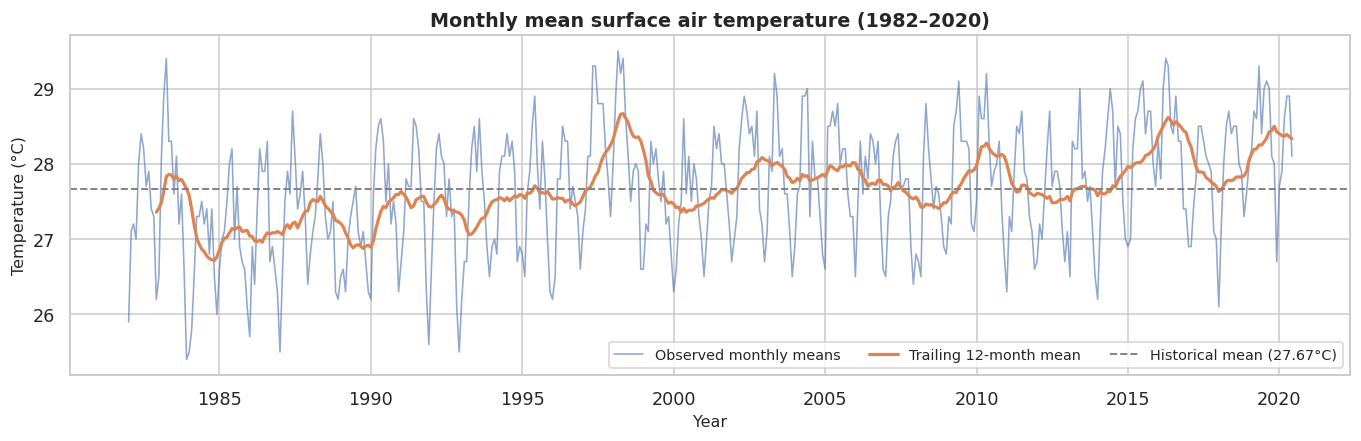

Monthly mean: 27.67°C | min: 25.40°C | max: 29.50°C


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 150, "axes.titleweight":"bold", "axes.labelsize": 10})
FIG_DIR = FILE_PATH.parent / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
series = df.set_index("month")["mean_temp"].asfreq("MS").astype(float)
assert series.notna().all(), "Unexpected missing months in temperature series"

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index,series,alpha=.62,lw=1,label="Observed monthly means")
ax.plot(series.rolling(12).mean(),lw=2,label="Trailing 12-month mean")
ax.axhline(series.mean(),linestyle="--",lw=1.2,color="gray",label=f"Historical mean ({series.mean():.2f}°C)")
ax.set(title="Monthly mean surface air temperature (1982–2020)",xlabel="Year",ylabel="Temperature (°C)")
ax.legend(ncol=3,fontsize=9); fig.tight_layout();fig.savefig(FIG_DIR/"01_historical_series.png");plt.show()
print(f"Monthly mean: {series.mean():.2f}°C | min: {series.min():.2f}°C | max: {series.max():.2f}°C")

### Interpretation — Long-run series

The line shows month-to-month variation and the trailing-average curve emphasizes lower-frequency movement. The graph is **descriptive**: any apparent long-term rise or fall should be assessed alongside uncertainty and potential non-climatic influences before being characterized as a statistically significant trend.

### Univariate distribution and unusual observations

**Why examine distributions?** A histogram shows how frequently different monthly means occur, while a boxplot highlights potential unusual observations. An IQR-based outlier flag is a descriptive rule, **not an automatic reason to delete climate measurements**.

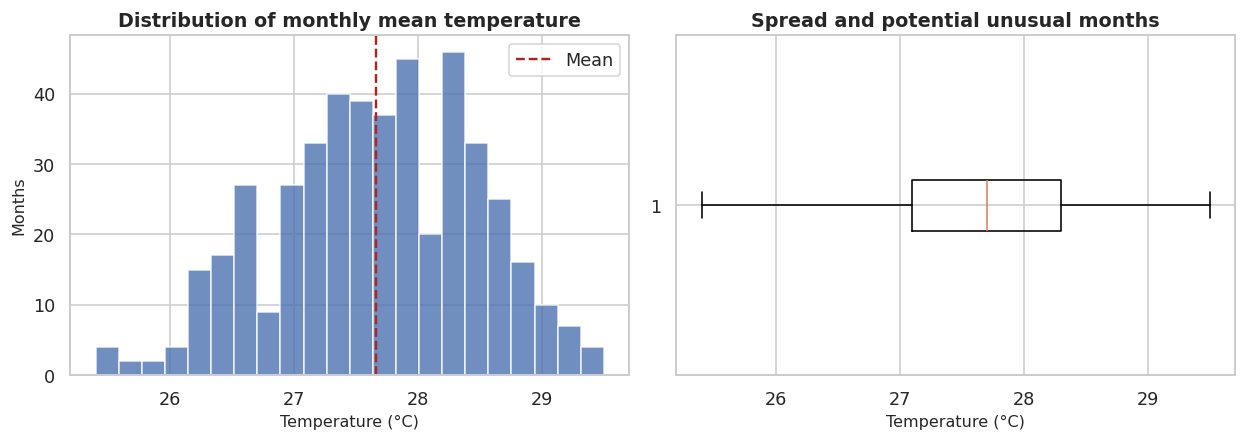

Standard deviation: 0.808°C | IQR: 1.20°C | IQR-flagged months: 0


In [7]:
q1,q3=series.quantile([.25,.75]);iqr=q3-q1
lower,upper=q1-1.5*iqr,q3+1.5*iqr
outliers=series[(series<lower)|(series>upper)]
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(series.to_numpy(),bins=22,alpha=.8);axes[0].axvline(series.mean(),color="firebrick",ls="--",label="Mean")
axes[0].set(title="Distribution of monthly mean temperature",xlabel="Temperature (°C)",ylabel="Months");axes[0].legend()
axes[1].boxplot(series.to_numpy(),vert=False);axes[1].set(title="Spread and potential unusual months",xlabel="Temperature (°C)")
fig.tight_layout();fig.savefig(FIG_DIR/"02_distribution_boxplot.png");plt.show()
print(f"Standard deviation: {series.std():.3f}°C | IQR: {iqr:.2f}°C | IQR-flagged months: {len(outliers)}")
if len(outliers):display(outliers.rename("temperature_C").to_frame().head(12))

### Interpretation — Variation

The distribution visualizes the temperature range and its concentration near the historical mean. Flagged months are retained: low/high temperatures may be legitimate measurements rather than data errors. Any automated outlier treatment would require contextual verification.

### Monthly climatology and seasonal contrasts

**Climatology** summarizes the temperature for each calendar month across years. Grouped monthly mean, median, standard deviation and sample size reveal both the average seasonal cycle and interannual uncertainty. Because the series ends in June 2020, January–June have one more observation than July–December.

,mean,median,std,min,max,count
month,,,,,,
Jan,26.682,26.60,0.620,25.5,28.3,39
Feb,27.246,27.20,0.649,25.8,28.9,39
Mar,27.705,27.70,0.776,26.3,29.5,39
Apr,28.118,28.10,0.600,27.0,29.4,39
May,28.464,28.50,0.523,27.3,29.4,39
Jun,28.418,28.40,0.439,27.5,29.3,39
Jul,28.053,28.10,0.504,27.0,29.1,38
Aug,27.966,27.95,0.492,27.0,29.1,38
Sep,27.818,27.90,0.541,26.7,29.0,38


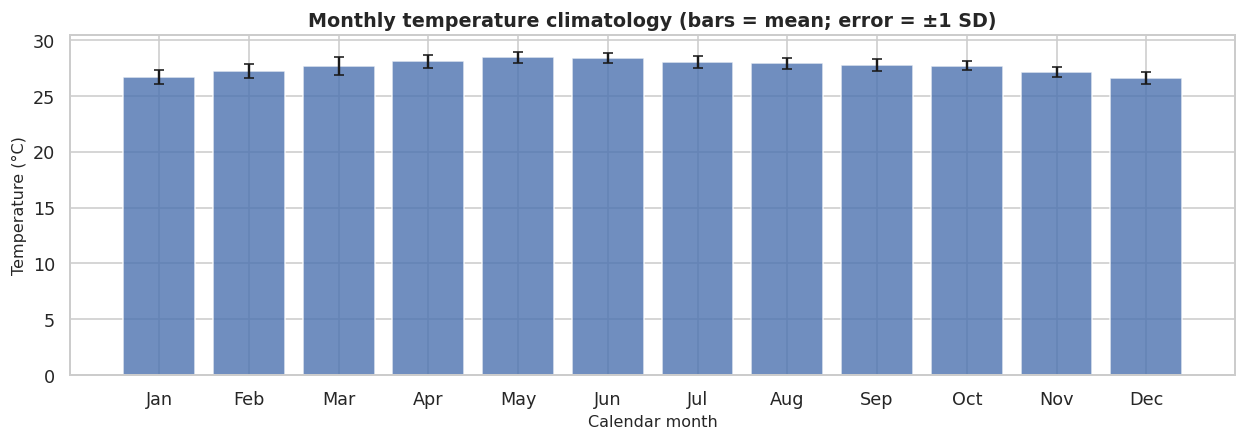

Warmest calendar month by mean: May (28.46°C)
Coolest calendar month by mean: Dec (26.63°C)
Average seasonal contrast: 1.84°C


In [8]:
season_frame=series.to_frame("mean_temp");season_frame["month_number"]=season_frame.index.month
season_frame["year"]=season_frame.index.year
monthly_stats=season_frame.groupby("month_number")["mean_temp"].agg(["mean","median","std","min","max","count"])
monthly_stats.index=pd.Index([pd.Timestamp(2000,m,1).strftime("%b") for m in monthly_stats.index],name="month")
display(monthly_stats.round(3))
fig,ax=plt.subplots(figsize=(11,4))
ax.bar(monthly_stats.index,monthly_stats["mean"],yerr=monthly_stats["std"],capsize=3,alpha=.8)
ax.set(title="Monthly temperature climatology (bars = mean; error = ±1 SD)",ylabel="Temperature (°C)",xlabel="Calendar month")
fig.tight_layout();fig.savefig(FIG_DIR/"03_monthly_climatology.png");plt.show()
warm=monthly_stats["mean"].idxmax();cool=monthly_stats["mean"].idxmin()
print(f"Warmest calendar month by mean: {warm} ({monthly_stats.loc[warm,'mean']:.2f}°C)")
print(f"Coolest calendar month by mean: {cool} ({monthly_stats.loc[cool,'mean']:.2f}°C)")
print(f"Average seasonal contrast: {monthly_stats['mean'].max()-monthly_stats['mean'].min():.2f}°C")

### Interpretation — Seasonal climatology

Mean temperatures differ systematically by calendar month. The monthly standard-deviation bars describe *year-to-year spread*, not confidence intervals for future forecasts. This climatology provides a simple benchmark for examining whether more complex methods add useful information.

### Month-wise distribution and year–month heatmap

A month-wise boxplot shows variability within each calendar month, rather than only its mean. The heatmap places years on rows and months on columns so recurring seasonal patterns and unusually warm/cool periods can be visually distinguished. **The partial 2020 year must not be treated as complete**.

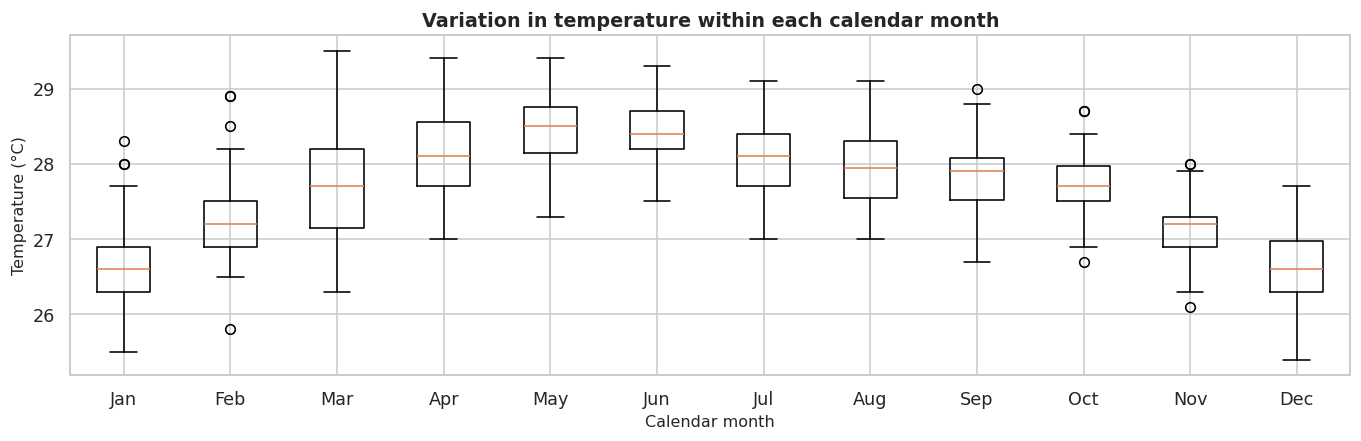

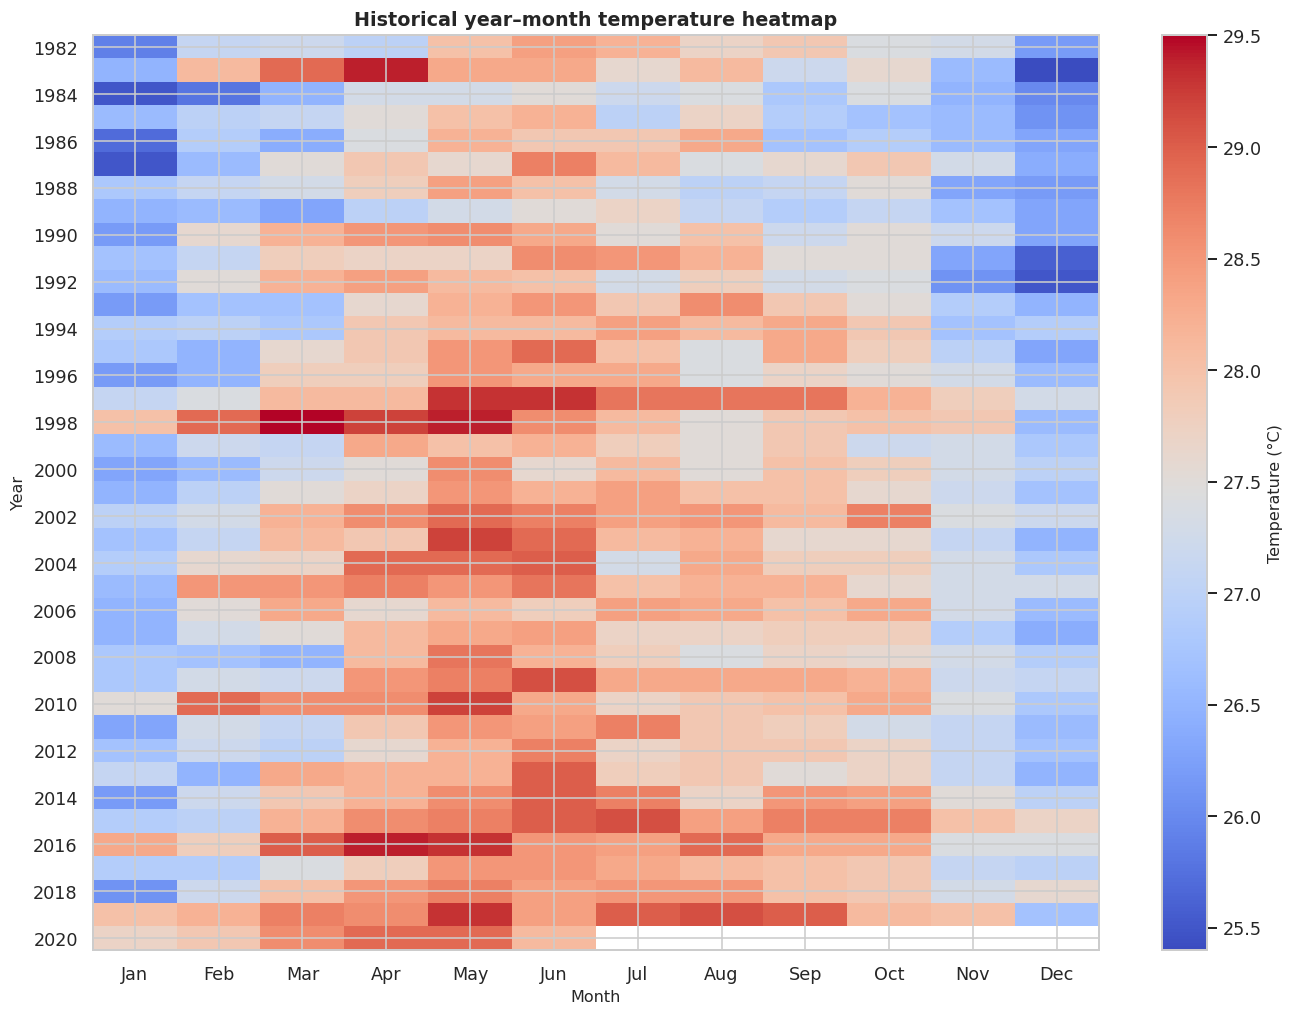

In [9]:
fig,ax=plt.subplots(figsize=(12,4))
ax.boxplot([season_frame.loc[season_frame["month_number"]==m,"mean_temp"].to_numpy() for m in range(1,13)])
ax.set(title="Variation in temperature within each calendar month",xlabel="Calendar month",ylabel="Temperature (°C)")
ax.set_xticks(range(1,13),[pd.Timestamp(2000,m,1).strftime("%b") for m in range(1,13)])
fig.tight_layout();fig.savefig(FIG_DIR/"04_monthly_boxplots.png");plt.show()
pivot=season_frame.pivot(index="year",columns="month_number",values="mean_temp").rename(columns={m:pd.Timestamp(2000,m,1).strftime("%b") for m in range(1,13)})
fig,ax=plt.subplots(figsize=(12,9))
img=ax.imshow(pivot.to_numpy(),aspect="auto",cmap="coolwarm",vmin=series.min(),vmax=series.max());fig.colorbar(img,ax=ax,label="Temperature (°C)");ax.set_xticks(range(12),list(pivot.columns));ax.set_yticks(range(len(pivot.index))[::2],list(pivot.index[::2]))
ax.set(title="Historical year–month temperature heatmap",xlabel="Month",ylabel="Year")
fig.tight_layout();fig.savefig(FIG_DIR/"05_year_month_heatmap.png");plt.show()

### Interpretation — Within-month variability

Boxes summarize the spread around each month's typical value. In the heatmap, continuous differences between columns suggest regular seasonality while differences between rows indicate year-to-year variation. Blank cells in July–December 2020 are due to the **known end of the source data**, not accidental missing values.

### Annual averages and trend assessment

Annual means are computed from **complete calendar years only** to avoid comparing the six-month year 2020 against full years. A simple linear fit is shown as a descriptive trend estimate; its p-value is **not used to establish causal warming**. Autocorrelation and station changes can complicate the usual independence assumptions.

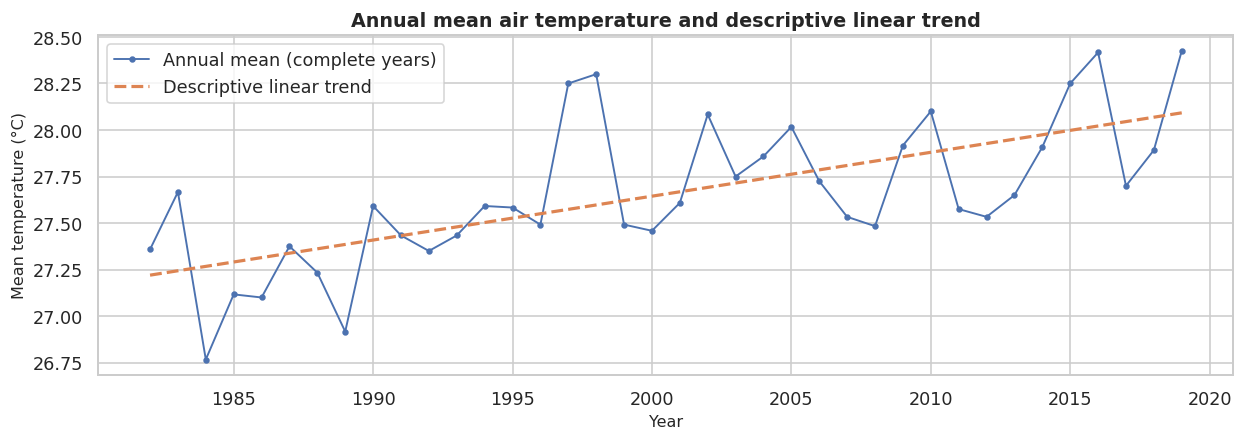

Complete years: 1982–2019 (38 years)
Linear slope: 0.0236°C per year (0.236°C per decade)
Naive linear-fit p-value: 4.657e-06; interpret cautiously due to temporal dependence


In [10]:
from scipy.stats import linregress
annual=season_frame.groupby("year")["mean_temp"].agg(["mean","count"])
annual_full=annual.loc[annual["count"]==12,"mean"]
trend=linregress(annual_full.index.to_numpy(dtype=float),annual_full.to_numpy())
trend_values=trend.intercept+trend.slope*annual_full.index.to_numpy(dtype=float)
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(annual_full.index,annual_full.values,marker="o",markersize=3,lw=1.2,label="Annual mean (complete years)")
ax.plot(annual_full.index,trend_values,ls="--",lw=2,label="Descriptive linear trend")
ax.set(title="Annual mean air temperature and descriptive linear trend",xlabel="Year",ylabel="Mean temperature (°C)")
ax.legend();fig.tight_layout();fig.savefig(FIG_DIR/"06_annual_trend.png");plt.show()
print(f"Complete years: {annual_full.index.min()}–{annual_full.index.max()} ({len(annual_full)} years)")
print(f"Linear slope: {trend.slope:.4f}°C per year ({trend.slope*10:.3f}°C per decade)")
print(f"Naive linear-fit p-value: {trend.pvalue:.4g}; interpret cautiously due to temporal dependence")

### Interpretation — Long-term changes

The slope quantifies the direction and approximate magnitude of the historical linear association between time and annual temperature. It is **not** evidence of a particular causal mechanism. The series is from one location and does not, by itself, quantify nationwide climate change.

### STL decomposition of level, seasonality and residuals

**STL (Seasonal-Trend decomposition using LOESS)** approximates an observed monthly series as `trend + seasonal + residual`. For monthly data we use `period=12`, allowing the seasonal cycle to repeat annually. Robust fitting reduces the influence of unusually extreme points. The three components should be interpreted as *estimated patterns*, not immutable truths or future observations.

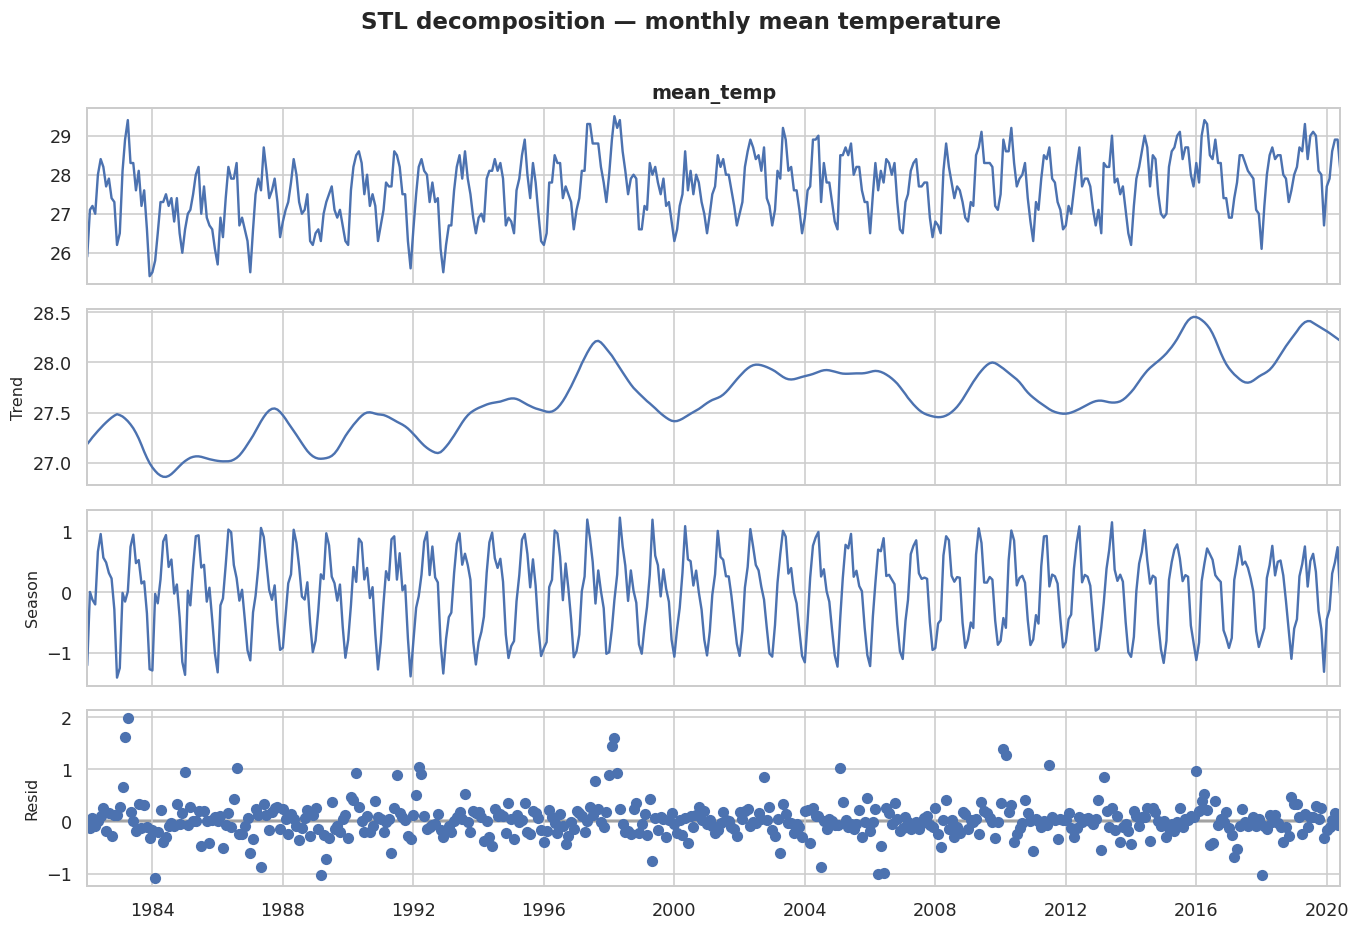

STL seasonal strength (descriptive): 0.759
STL trend strength (descriptive): 0.565


In [11]:
stl_result=STL(series,period=12,robust=True).fit()
fig=stl_result.plot();fig.set_size_inches(12,8)
fig.suptitle("STL decomposition — monthly mean temperature",y=1.01,fontweight="bold")
fig.tight_layout();fig.savefig(FIG_DIR/"07_stl_decomposition.png",bbox_inches="tight");plt.show()
strength_season=max(0,1-np.var(stl_result.resid)/np.var(stl_result.resid+stl_result.seasonal))
strength_trend=max(0,1-np.var(stl_result.resid)/np.var(stl_result.resid+stl_result.trend))
print(f"STL seasonal strength (descriptive): {strength_season:.3f}")
print(f"STL trend strength (descriptive): {strength_trend:.3f}")

### Interpretation — Decomposed components

The seasonal component displays recurring intra-year structure; the trend component extracts smoother longer-term variation, and the residual contains remaining irregular movements. The strength indicators are descriptive summaries that depend on decomposition settings. **STL is calculated on the historical series for EDA only**; decomposition must not be fitted on held-out future observations as part of model training.

### Autocorrelation and partial autocorrelation (ACF / PACF)

**ACF** measures how observations separated by `k` months move together. **PACF** measures their remaining association after accounting for intervening lags. Peaks around 12 or 24 months can suggest annual structure, while low-lag correlations indicate short-term persistence. These are **diagnostic inputs**, not proof of the optimal SARIMA specification.

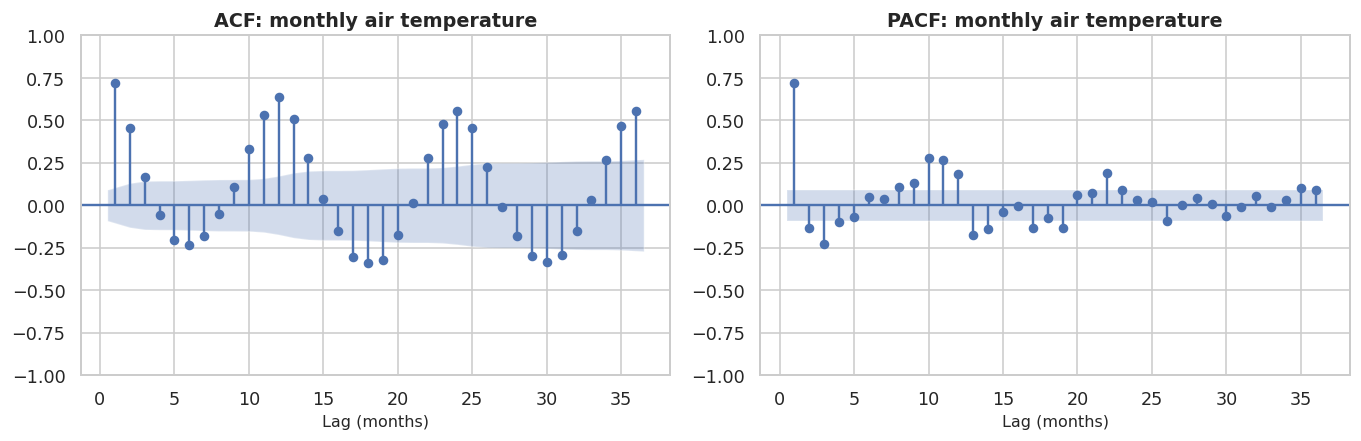

ACF lag 1: 0.719; lag 12: 0.635; lag 24: 0.553


In [12]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
plot_acf(series,lags=36,ax=axes[0],zero=False);axes[0].set(title="ACF: monthly air temperature",xlabel="Lag (months)")
plot_pacf(series,lags=36,ax=axes[1],zero=False,method="ywm");axes[1].set(title="PACF: monthly air temperature",xlabel="Lag (months)")
fig.tight_layout();fig.savefig(FIG_DIR/"08_acf_pacf.png");plt.show()
a=acf(series,nlags=24,fft=True)
print(f"ACF lag 1: {a[1]:.3f}; lag 12: {a[12]:.3f}; lag 24: {a[24]:.3f}")

#### Evidence-based summary

The summary below is **computed from the observations**, rather than copied from a generic description. It highlights the typical monthly cycle, degree of historical variation, estimated annual trend and seasonality diagnostics. None of these findings is used to select a forecasting model yet.

In [13]:
eda_findings = pd.DataFrame([
    ("Period",f"{series.index.min():%Y-%m} to {series.index.max():%Y-%m}"),
    ("Monthly observations",f"{len(series)}"),
    ("Mean temperature",f"{series.mean():.2f} °C"),
    ("Standard deviation",f"{series.std():.2f} °C"),
    ("Warmest calendar month",f"{warm} ({monthly_stats.loc[warm,'mean']:.2f} °C)"),
    ("Coolest calendar month",f"{cool} ({monthly_stats.loc[cool,'mean']:.2f} °C)"),
    ("Seasonal mean contrast",f"{monthly_stats['mean'].max()-monthly_stats['mean'].min():.2f} °C"),
    ("Annual linear slope",f"{trend.slope*10:.3f} °C per decade"),
    ("STL seasonal strength",f"{strength_season:.3f}"),
    ("ACF lag 12",f"{a[12]:.3f}"),
],columns=["Indicator","Observed finding"])
display(eda_findings)
eda_findings.to_csv(FILE_PATH.parent/"outputs"/"eda_summary.csv",index=False)
monthly_stats.to_csv(FILE_PATH.parent/"outputs"/"monthly_climatology.csv")
print("Saved summary tables and eight figures under outputs/.")

,Indicator,Observed finding
0,Period,1982-01 to 2020-06
1,Monthly observations,462
2,Mean temperature,27.67 °C
3,Standard deviation,0.81 °C
4,Warmest calendar month,May (28.46 °C)
5,Coolest calendar month,Dec (26.63 °C)
6,Seasonal mean contrast,1.84 °C
7,Annual linear slope,0.236 °C per decade
8,STL seasonal strength,0.759
9,ACF lag 12,0.635


Saved summary tables and eight figures under outputs/.


#### EDA Conclusion and Preparation for Modeling

**What has been established:** descriptive distribution, seasonal month-by-month behavior, complete-year temperature trajectory, estimated STL components, and lag-dependence diagnostics. The summary table above provides reproducible numeric evidence.

**What remains deliberately unresolved:** the most accurate forecasting model, feature usefulness, and out-of-sample forecasting error. These can only be answered by chronological validation.

**Next — Feature Engineering & Experimental Design:** design calendar, lag, rolling, and trend features; define 12-month expanding-window backtests; and lock an untouched test period (January 2015–June 2020). Features will be computed only from information available at each prediction origin. The final historical 12-month projection will cover July 2020–June 2021.

## Stage 3 — Methodology and Baseline Development

**Purpose.** Translate the historical temperature series into a forecasting-ready dataset and design reproducible, **chronological** experiments before fitting any prediction model. This section introduces **no trained forecasting models**; it establishes the inputs, evaluation schedule, and leakage safeguards for candidate modeling.

**Key decisions.** The target is monthly mean temperature (°C). We forecast **12 months at once**, not just the next month. Model selection will use the 2010–2014 validation period; the 2015–June 2020 period is **reserved** for final evaluation in final evaluation.

**Research questions:** (1) What historical temperature information can genuinely be known at forecast time? (2) How should seasonality and a long-run trend be represented? (3) How can competing models be judged fairly without using future observations?

### Forecasting horizon and chronological partitions

Unlike randomly sampled classification tasks, a future temperature observation must **never enter the training set of an earlier forecast**. We define three consecutive time partitions. The validation period is for selecting configurations; the test period is not used to fit, tune or assess models in this section.

| Partition | Inclusive dates | Number of months | Function |
|:--|:--|--:|:--|
| Train | 1982-01 to 2009-12 | 336 | Fit initial candidates |
| Validation | 2010-01 to 2014-12 | 60 | Select features, hyperparameters, model family |
| Test (sealed) | 2015-01 to 2020-06 | 66 | Final unbiased comparison *after model selection* |

Our **12-month validation origins** will initially be 2009-12, 2011-12, and 2013-12; each produces a **full 12-month forecast** for 2010, 2012 or 2014 respectively. We intentionally use three spaced windows for fast model iteration; the remaining validation months may be used for additional rolling checks later, but never as test observations.

In [14]:
# Boundaries are explicit, so future data cannot be silently included.
TRAIN_END = pd.Timestamp("2009-12-01")
VALID_END = pd.Timestamp("2014-12-01")
TEST_END = pd.Timestamp("2020-06-01")
FORECAST_HORIZON = 12

train_series = series.loc[:TRAIN_END].copy()
validation_series = series.loc[TRAIN_END + pd.offsets.MonthBegin(1):VALID_END].copy()
# This slice is shown only to establish dates/counts; values will not be used in model selection.
sealed_test_dates = series.loc[VALID_END + pd.offsets.MonthBegin(1):TEST_END].index

assert len(train_series) == 336 and len(validation_series) == 60 and len(sealed_test_dates) == 66
assert train_series.index.max() < validation_series.index.min() < sealed_test_dates.min()
assert train_series.index.is_unique and series.index.is_monotonic_increasing
split_summary = pd.DataFrame([
    {"Partition":"Training", "Start":train_series.index.min().strftime("%Y-%m"), "End":train_series.index.max().strftime("%Y-%m"), "Months":len(train_series)},
    {"Partition":"Validation", "Start":validation_series.index.min().strftime("%Y-%m"), "End":validation_series.index.max().strftime("%Y-%m"), "Months":len(validation_series)},
    {"Partition":"Sealed test (dates only)", "Start":sealed_test_dates.min().strftime("%Y-%m"), "End":sealed_test_dates.max().strftime("%Y-%m"), "Months":len(sealed_test_dates)},
])
display(split_summary)


,Partition,Start,End,Months
0,Training,1982-01,2009-12,336
1,Validation,2010-01,2014-12,60
2,Sealed test (dates only),2015-01,2020-06,66


### Interpretation — Why these boundaries matter

The 336 initial months give statistical methods many annual cycles to learn from. The validation periods represent genuine historical forecasting exercises: only past observations are available at each forecast origin. The 66 reserved test months must remain untouched until model configurations have been frozen. Reporting a good validation score is **not** equivalent to reporting final generalization performance.

### Feature categories and theoretical rationale

A time-indexed supervised-learning model needs numerical inputs. We use three types:

1. **Calendar and trend:** `month_sin` and `month_cos` encode the circular year (December is adjacent to January), while `time_index` represents elapsed months since 1982-01. These are available in advance and may be used for any forecast horizon.
2. **Lag values:** `lag_1`, `lag_3`, `lag_6`, and `lag_12` represent previous monthly mean temperatures. The 12-month lag is a direct annual-seasonality indicator.
3. **Historical rolling statistics:** means across 3, 6, and 12 **previous** months, and standard deviation across the previous 12 months. These smooth recent variation without looking ahead.

The **past-only rolling average** at time `t` is the mean of observations `t−1, t−2, …, t−k`; it excludes the observation at month `t`.

**Crucially,** lag and rolling inputs are only known for future dates when their required history is available. Multi-month forecasts therefore need a recursive strategy or horizon-specific features. *We will implement that strategy in candidate modeling.*

In [15]:
# This function only constructs features; it does not fit a model.
FEATURE_COLUMNS = [
    "month_sin", "month_cos", "time_index",
    "lag_1", "lag_3", "lag_6", "lag_12",
    "rolling_mean_3", "rolling_mean_6", "rolling_mean_12", "rolling_std_12"
]

def make_temperature_features(temperature_history: pd.Series) -> pd.DataFrame:
    """Create dated, past-only predictors; includes NaNs for insufficient history."""
    y = temperature_history.astype(float).sort_index().copy()
    if not isinstance(y.index, pd.DatetimeIndex) or y.index.has_duplicates:
        raise ValueError("Expected a unique DatetimeIndex")
    if not (y.index.to_period("M") == pd.period_range(y.index.min(), y.index.max(), freq="M")).all():
        raise ValueError("Monthly index must be consecutive")
    x = pd.DataFrame(index=y.index)
    x["month_sin"] = np.sin(2 * np.pi * x.index.month / 12)
    x["month_cos"] = np.cos(2 * np.pi * x.index.month / 12)
    x["time_index"] = (x.index.year - 1982) * 12 + (x.index.month - 1)
    for lag in (1, 3, 6, 12):
        x[f"lag_{lag}"] = y.shift(lag)
    past_only = y.shift(1)
    for window in (3, 6, 12):
        x[f"rolling_mean_{window}"] = past_only.rolling(window=window, min_periods=window).mean()
    x["rolling_std_12"] = past_only.rolling(window=12, min_periods=12).std()
    return x

# Only TRAINING data is used in the development preview below.
training_features = make_temperature_features(train_series)
training_supervised = training_features.assign(target_mean_temp=train_series).dropna()
print(f"Feature columns: {len(FEATURE_COLUMNS)}; training rows after lags: {len(training_supervised)}")
display(training_supervised.head(4).round(3))
assert list(training_features.columns) == FEATURE_COLUMNS
assert training_supervised.index.max() <= TRAIN_END


Feature columns: 11; training rows after lags: 324


,month_sin,month_cos,time_index,lag_1,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_12,target_mean_temp
month,,,,,,,,,,,,
1983-01-01,0.500,0.866,12,26.2,27.4,28.2,25.9,26.967,27.450,27.358,0.757,26.5
1983-02-01,0.866,0.500,13,26.5,27.3,27.7,27.1,26.667,27.167,27.408,0.667,28.1
1983-03-01,1.000,0.000,14,28.1,26.2,27.9,27.2,26.933,27.233,27.492,0.687,28.9
1983-04-01,0.866,-0.500,15,28.9,26.5,27.4,27.0,27.833,27.400,27.633,0.789,29.4


### Interpretation — First usable feature row

The first 12 months cannot have a complete 12-month history, so they are intentionally dropped **from supervised training**, not filled using future data. This leaves 324 complete training examples (1983-01 through 2009-12). Traditional SARIMA and Holt-Winters can still use the entire original training series because they do not require this supervised feature table. We will not scale or impute across the full dataset; any learned transformations must be fitted using the training portion only.

### Visualize engineered training features

The plot illustrates the relationship between observed temperature, its one-year lag, and the trailing 12-month average. This is **descriptive of training data only**, not proof that either feature will improve forecast accuracy.

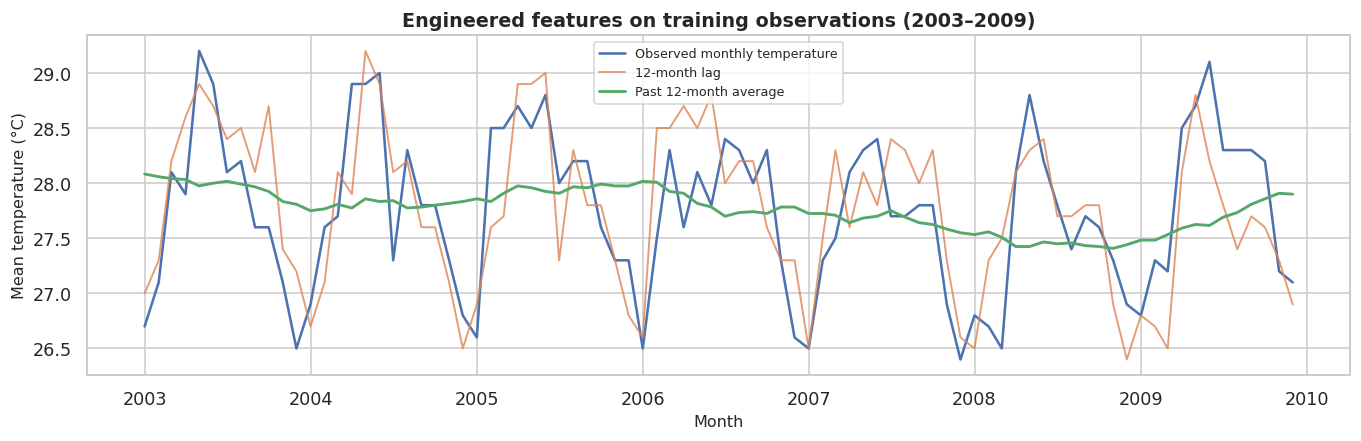

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
recent = training_supervised.loc["2003-01":"2009-12"]
ax.plot(recent.index, recent["target_mean_temp"], label="Observed monthly temperature", lw=1.6)
ax.plot(recent.index, recent["lag_12"], label="12-month lag", lw=1.2, alpha=.8)
ax.plot(recent.index, recent["rolling_mean_12"], label="Past 12-month average", lw=1.8)
ax.set(title="Engineered features on training observations (2003–2009)", xlabel="Month", ylabel="Mean temperature (°C)")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "m3_training_feature_examples.png", bbox_inches="tight")
plt.show()


### Safeguards: prove feature construction does not look ahead

We will test that changing a target value in a later month **cannot change any earlier feature rows**. We also verify that `lag_1` and the rolling mean reproduce simple manually calculated values. These checks are more important than achieving a superficially high score: a leaked temperature feature can produce an unrealistically optimistic forecast.

In [17]:
# Perform tests on training history, without touching the reserved test values.
original_features = make_temperature_features(train_series)
perturbed_history = train_series.copy()
perturbed_history.loc[pd.Timestamp("2008-06-01")] += 15.0
perturbed_features = make_temperature_features(perturbed_history)

pd.testing.assert_frame_equal(
    original_features.loc[:"2008-06-01"],
    perturbed_features.loc[:"2008-06-01"],
    check_exact=True,
)
check_date = pd.Timestamp("2009-01-01")
assert np.isclose(original_features.loc[check_date, "lag_1"], train_series.loc["2008-12-01"])
assert np.isclose(original_features.loc[check_date, "lag_12"], train_series.loc["2008-01-01"])
assert np.isclose(original_features.loc[check_date, "rolling_mean_3"], train_series.loc["2008-10":"2008-12"].mean())
assert original_features.iloc[:12]["rolling_mean_12"].isna().all()
print("PASSED: chronological features use only preceding observations.")


PASSED: chronological features use only preceding observations.


### Expanding-window, 12-month validation design

At each origin we train or refit on all observed data available **through that origin** and predict the next 12 months. Between validation origins, additional previously observed months are allowed into history. This mimics what a forecaster could have done at the time.

| Origin (training ends) | Forecasted months | Horizon |
|:--|:--|--:|
| 2009-12 | 2010-01 through 2010-12 | 12 |
| 2011-12 | 2012-01 through 2012-12 | 12 |
| 2013-12 | 2014-01 through 2014-12 | 12 |

**No model is trained in this section.** The next modeling section will use the same folds for Seasonal Naive, Ridge Regression, Holt-Winters, SARIMA, and XGBoost. For ML models, month-ahead lag features will be calculated recursively using the model's earlier predictions, not the unknown actual future observations.

In [18]:
VALIDATION_ORIGINS = pd.to_datetime(["2009-12-01", "2011-12-01", "2013-12-01"])
folds = []
for fold_no, origin in enumerate(VALIDATION_ORIGINS, start=1):
    horizon_dates = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=FORECAST_HORIZON, freq="MS")
    assert origin < horizon_dates.min()
    assert (horizon_dates.max() <= VALID_END) and (horizon_dates.min() >= pd.Timestamp("2010-01-01"))
    observed_history = series.loc[:origin]
    assert len(observed_history) >= len(train_series)
    folds.append({
        "Fold": fold_no,
        "History through": origin.strftime("%Y-%m"),
        "History months": len(observed_history),
        "Forecast from": horizon_dates.min().strftime("%Y-%m"),
        "Forecast through": horizon_dates.max().strftime("%Y-%m"),
        "Forecast months": len(horizon_dates),
    })
validation_fold_table = pd.DataFrame(folds)
display(validation_fold_table)
assert validation_fold_table["Forecast months"].sum() == 36


,Fold,History through,History months,Forecast from,Forecast through,Forecast months
0,1,2009-12,336,2010-01,2010-12,12
1,2,2011-12,360,2012-01,2012-12,12
2,3,2013-12,384,2014-01,2014-12,12


### Pre-registered evaluation metrics and model fairness

Every candidate must forecast the *same* months in the *same* validation folds.

- **MAE (°C):** mean of `abs(actual − forecast)`; primary metric because it is easy to interpret.
- **RMSE (°C):** square root of the mean of `(actual − forecast)²`; penalizes large misses more strongly.
- **Bias (°C):** mean of `(forecast − actual)`; positive indicates overprediction, negative underprediction.
- **Runtime:** records training and forecasting cost for practical comparison.

**Selection rule:** Lowest validation MAE wins. RMSE, bias, and implementation simplicity serve as secondary considerations. No test-set scores will influence selection or tuning. We will produce the final 12-month projection only after model selection is complete.

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def forecast_metrics(y_true, y_pred) -> dict:
    """Temperature forecast quality on a common set of dates (units: °C)."""
    observed = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)
    if observed.shape != predicted.shape or not np.isfinite(predicted).all():
        raise ValueError("Predictions must match target shape and contain finite values")
    return {
        "MAE (°C)": float(mean_absolute_error(observed, predicted)),
        "RMSE (°C)": float(np.sqrt(mean_squared_error(observed, predicted))),
        "Bias (°C)": float(np.mean(predicted - observed)),
    }

# Sanity check only: identical values imply zero error. No forecasting model is fitted here.
assert forecast_metrics([27., 28.], [27., 28.]) == {"MAE (°C)": 0.0, "RMSE (°C)": 0.0, "Bias (°C)": 0.0}
print("Metric functions defined and validated; ready for candidate model development.")


Metric functions defined and validated; ready for candidate model development.


### Save experimental artifacts and conclusion

For reproducibility, export the *training-only* supervised table, split summary, and validation schedule. The CSVs contain **no reserved test observations**. The notebook remains portable: all outputs are saved beside the source dataset in the `outputs` folder.

In [20]:
training_supervised.rename_axis("month").to_csv(output_dir / "m3_training_features.csv", date_format="%Y-%m")
split_summary.to_csv(output_dir / "m3_data_partitions.csv", index=False)
validation_fold_table.to_csv(output_dir / "m3_validation_folds.csv", index=False)
print("Saved feature preview, partitions and validation folds under:", output_dir)


Saved feature preview, partitions and validation folds under: /mnt/data/Air-Temperature-Time-Series/outputs


#### Findings and handoff

- **11 engineered features** have been specified and generated from training data: 2 cyclical calendar variables, 1 elapsed-time trend, 4 lags and 4 past-only rolling statistics.
- **324** full-feature training rows remain after removing 12 months without sufficient history. This is intentional, not missing-data imputation.
- The **336 / 60 / 66** month train/validation/test split is fixed; final test months were used only to count and label the reserved period.
- Three **12-month expanding-window folds** define the initial model-selection experiment, for a total of **36 validation forecasts per candidate**.
- Direct future observations are prohibited as model inputs. Multi-step ML prediction must be implemented recursively or with horizon-specific predictors.

**Next: candidate modeling — Forecasting Model Development.** Fit and compare Seasonal Naive, Ridge Regression, Holt-Winters, SARIMA and XGBoost using the predefined validation folds. Keep the complete test period unopened until final evaluation.

### Candidate Forecasting Models and Initial Validation

**Objective.** Build five distinct forecasting models and compare their performance on *the same* 36 validation months (2010, 2012, and 2014). We optimize for reproducible out-of-sample accuracy, **not** an inflated in-sample score. Final test observations (2015–June 2020) remain sealed until final evaluation.

**Evaluation matrix.** Each model is judged by MAE (primary, °C), RMSE (°C), mean bias (°C), percentage improvement over the seasonal-naive baseline, validation-fold variability, and runtime. A lower error is better; bias near zero is desirable. Temperature forecasting does not have a useful universal classification-style "accuracy percentage".

**Fairness.** Every 12-month forecast is generated once at its origin, without inserting the true temperatures observed later in that forecast year. For the machine-learning regressor, later months use earlier *predictions*, not observed future temperatures.

### Model families and comparison design

| Model | How it forecasts | Candidate settings |
|---|---|---|
| **Seasonal Naive** | Repeats the same month from the preceding year | Fixed baseline |
| **Ridge Regression** | Learns a regularized linear time trend and month seasonality | Several regularization strengths |
| **Holt–Winters** | Smooths the historical level, possible trend, and annual seasonality | No trend vs additive trend |
| **SARIMA** | Models serial and yearly dependence statistically | Small, predeclared seasonal order set |
| **XGBoost** | Learns nonlinear relationships from past-only engineered features | Conservative tree depths |

**Why tune only a few configurations?** With 462 observations, exhaustive tuning increases cost and selection overfitting. We use a deliberately compact candidate list. The comparison itself does not touch the test set.

In [21]:
import time
import warnings
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

# Fixed configurations declared before examining validation scores.
MODEL_CANDIDATES = {
    "Seasonal Naive": {"default": {}},
    "Ridge": {f"alpha={a:g}": {"alpha": a} for a in (1.0, 20.0)},
    "Holt-Winters": {
        "seasonal/no-trend": {"trend": None},
        "seasonal/additive-trend": {"trend": "add"},
    },
    "SARIMA": {
        "(1,0,0)(1,0,0)[12]": {"order": (1,0,0), "seasonal_order": (1,0,0,12)},
        "(1,0,1)(1,0,0)[12]": {"order": (1,0,1), "seasonal_order": (1,0,0,12)},
    },
    "XGBoost": {
        "depth=2": {"max_depth": 2},
        "depth=3": {"max_depth": 3},
    },
}
print("Candidate configurations:", sum(len(v) for v in MODEL_CANDIDATES.values()))
assert VALID_END < sealed_test_dates.min()


Candidate configurations: 9


### Leak-free forecasting functions

**Statistical models** are fitted using only the available history at the forecast origin. Ridge uses month sin/cos and a deterministic time index, all known for future dates. **XGBoost** is trained on the 11 engineered features; each forecast step builds the next row from observed history and the model's previously forecast months. This recursive design prevents future-temperature leakage.

The forecasting functions return *twelve predicted values*, with no access to future target values.

In [22]:
RIDGE_COLUMNS = ["month_sin", "month_cos", "time_index"]

def future_calendar_features(dates):
    idx = pd.DatetimeIndex(dates)
    return pd.DataFrame({
        "month_sin": np.sin(2*np.pi*idx.month/12),
        "month_cos": np.cos(2*np.pi*idx.month/12),
        "time_index": (idx.year-1982)*12+(idx.month-1),
    }, index=idx)

def forecast_candidate(history, model_name, parameters, horizon=12):
    history = history.astype(float).sort_index()
    future_dates = pd.date_range(history.index[-1]+pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    if model_name == "Seasonal Naive":
        return pd.Series([history.loc[d-pd.DateOffset(years=1)] for d in future_dates], index=future_dates)
    if model_name == "Ridge":
        train_x = future_calendar_features(history.index)
        estimator = make_pipeline(StandardScaler(), Ridge(alpha=parameters["alpha"]))
        estimator.fit(train_x[RIDGE_COLUMNS], history.to_numpy())
        predictions = estimator.predict(future_calendar_features(future_dates)[RIDGE_COLUMNS])
        return pd.Series(predictions, index=future_dates)
    if model_name == "Holt-Winters":
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            model = ExponentialSmoothing(history, trend=parameters["trend"], seasonal="add", seasonal_periods=12, initialization_method="estimated")
            fitted = model.fit(optimized=True)
        return pd.Series(fitted.forecast(horizon).to_numpy(), index=future_dates)
    if model_name == "SARIMA":
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=UserWarning)
            model = SARIMAX(history, order=parameters["order"], seasonal_order=parameters["seasonal_order"], trend="c", enforce_stationarity=False, enforce_invertibility=False)
            fitted = model.fit(disp=False, maxiter=75)
        return pd.Series(np.asarray(fitted.forecast(horizon)), index=future_dates)
    if model_name == "XGBoost":
        features = make_temperature_features(history)
        supervised = features.assign(y=history).dropna()
        estimator = XGBRegressor(n_estimators=180, max_depth=parameters["max_depth"], learning_rate=0.04,
                                 subsample=0.9, colsample_bytree=0.9, objective="reg:squarederror", n_jobs=2,
                                 reg_lambda=5.0, random_state=42)
        estimator.fit(supervised[FEATURE_COLUMNS], supervised["y"])
        evolving_history = history.copy()
        future_values = []
        for date in future_dates:
            # A missing placeholder creates lag/rolling inputs from available past only.
            placeholder = pd.concat([evolving_history, pd.Series([np.nan], index=pd.DatetimeIndex([date]))])
            row = make_temperature_features(placeholder).loc[[date], FEATURE_COLUMNS]
            if row.isna().any().any():
                raise ValueError("Missing features in recursive XGBoost forecast")
            prediction = float(estimator.predict(row)[0])
            future_values.append(prediction)
            evolving_history.loc[date] = prediction
        return pd.Series(future_values, index=future_dates)
    raise ValueError(f"Unknown model: {model_name}")

# Check outputs are the correct shape and arise after the known history.
smoke_history = series.loc[:TRAIN_END]
smoke = forecast_candidate(smoke_history, "Seasonal Naive", {}, 12)
assert len(smoke)==12 and smoke.index.min()>TRAIN_END and smoke.notna().all()
print("Forecasting function and initial chronological checks passed.")


Forecasting function and initial chronological checks passed.


### Expanding-window validation: run each model on identical months

At each origin, we refit using all **prior observed months**, forecast the next 12 months, and compute errors against observations **only after generating the full forecast**. Validation data becomes available as historical training information only at later, chronologically valid origins. The reserved test years are never accessed here.

We retain row-level forecast records for monthly error diagnostics in validation and refinement and report configuration-level performance using pooled errors over all 36 validation months.

In [23]:
validation_records = []
run_records = []
for model_name, configs in MODEL_CANDIDATES.items():
    for config_name, params in configs.items():
        started = time.perf_counter()
        for fold, origin in enumerate(VALIDATION_ORIGINS, start=1):
            historical = series.loc[:origin]
            predictions = forecast_candidate(historical, model_name, params, FORECAST_HORIZON)
            assert predictions.index.min()>origin and predictions.index.max()<=VALID_END
            actual = validation_series.reindex(predictions.index)
            assert actual.notna().all()
            for dt, pred, obs in zip(predictions.index, predictions.to_numpy(), actual.to_numpy()):
                validation_records.append({"model":model_name, "configuration":config_name, "fold":fold,
                                           "month":dt, "actual_C":float(obs), "predicted_C":float(pred),
                                           "error_C":float(pred-obs)})
        duration = time.perf_counter()-started
        run_records.append({"model":model_name, "configuration":config_name, "runtime_seconds":duration})
        print(f"{model_name:16} {config_name:26} {duration:6.2f} s")

validation_predictions = pd.DataFrame(validation_records)
runtimes = pd.DataFrame(run_records)
assert len(validation_predictions)==sum(map(len,MODEL_CANDIDATES.values()))*36
assert (validation_predictions.month<=VALID_END).all()
assert (validation_predictions.month<sealed_test_dates.min()).all()
print(f"Validation prediction records: {len(validation_predictions)}; unique validation months: {validation_predictions.month.nunique()}")


Seasonal Naive   default                      0.00 s


Ridge            alpha=1                      0.02 s
Ridge            alpha=20                     0.01 s


Holt-Winters     seasonal/no-trend            0.10 s


Holt-Winters     seasonal/additive-trend      0.43 s


SARIMA           (1,0,0)(1,0,0)[12]           1.39 s


SARIMA           (1,0,1)(1,0,0)[12]           1.71 s


XGBoost          depth=2                      0.32 s


XGBoost          depth=3                      0.32 s
Validation prediction records: 324; unique validation months: 36


### Evaluation matrix — accuracy, error direction, stability, and speed

**MAE** measures typical absolute error in °C, and is our primary ranking metric. **RMSE** penalizes larger mistakes. **Bias** is the average prediction-minus-observed temperature, showing systematic over- or under-prediction. **Baseline improvement** is relative to Seasonal Naive on exactly the same forecast months: positive means better. Fold-to-fold MAE spread is a descriptive measure of robustness; **runtime** reflects this machine and is not a universal benchmark.

For the official model selection we rank configurations by validation MAE. The *best configuration of each model family* enters the five-model comparison. We will not tune the final test set.

In [24]:
rows = []
for (model, config), g in validation_predictions.groupby(["model","configuration"],sort=False):
    met = forecast_metrics(g.actual_C, g.predicted_C)
    fold_maes = g.groupby("fold").apply(lambda t:float(np.mean(np.abs(t.error_C))),include_groups=False)
    rows.append({"Model":model,"Configuration":config, **met,
                 "Fold MAE SD (°C)":float(fold_maes.std(ddof=0)),
                 "Worst fold MAE (°C)":float(fold_maes.max())})
full_evaluation = pd.DataFrame(rows).merge(runtimes,left_on=["Model","Configuration"],right_on=["model","configuration"]).drop(columns=["model","configuration"])
baseline_mae = float(full_evaluation.loc[full_evaluation.Model=="Seasonal Naive","MAE (°C)"].iloc[0])
full_evaluation["Improvement vs baseline (%)"] = (baseline_mae-full_evaluation["MAE (°C)"])/baseline_mae*100
full_evaluation = full_evaluation.rename(columns={"runtime_seconds":"Runtime (s)"}).sort_values("MAE (°C)").reset_index(drop=True)

best_by_family = (full_evaluation.sort_values("MAE (°C)").drop_duplicates("Model")
                  .sort_values("MAE (°C)").reset_index(drop=True))
best_by_family.insert(0,"Rank",np.arange(1,len(best_by_family)+1))
print("Full candidate evaluation matrix")
display(full_evaluation.round(4))
print("Best configuration of each model family")
display(best_by_family.round(4))

# Rank selections only using validation measurements; no test values used.
SELECTED_CONFIGS = {row["Model"]:row["Configuration"] for _,row in best_by_family.iterrows()}
selected_best_name = str(best_by_family.iloc[0]["Model"])
print("Validation-selected family:",selected_best_name)


Full candidate evaluation matrix


,Model,Configuration,MAE (°C),RMSE (°C),Bias (°C),Fold MAE SD (°C),Worst fold MAE (°C),Runtime (s),Improvement vs baseline (%)
0,XGBoost,depth=2,0.3372,0.4735,-0.1448,0.1166,0.4528,0.3185,25.0648
1,XGBoost,depth=3,0.3422,0.4640,-0.1797,0.1216,0.4586,0.3206,23.9601
2,Holt-Winters,seasonal/additive-trend,0.3480,0.4418,-0.0890,0.1030,0.4256,0.4332,22.6641
3,Holt-Winters,seasonal/no-trend,0.3487,0.4433,-0.1034,0.1022,0.4226,0.0998,22.5089
4,SARIMA,"(1,0,0)(1,0,0)[12]",0.4246,0.5712,-0.2579,0.1210,0.5108,1.3943,5.6398
5,SARIMA,"(1,0,1)(1,0,0)[12]",0.4263,0.5732,-0.2620,0.1232,0.5140,1.7097,5.2751
6,Ridge,alpha=20,0.4369,0.5486,0.0720,0.0730,0.5329,0.0121,2.9073
7,Ridge,alpha=1,0.4406,0.5550,0.0910,0.0794,0.5385,0.0166,2.0786
8,Seasonal Naive,default,0.4500,0.5930,-0.1333,0.1389,0.5833,0.0033,0.0000


Best configuration of each model family


,Rank,Model,Configuration,MAE (°C),RMSE (°C),Bias (°C),Fold MAE SD (°C),Worst fold MAE (°C),Runtime (s),Improvement vs baseline (%)
0,1,XGBoost,depth=2,0.3372,0.4735,-0.1448,0.1166,0.4528,0.3185,25.0648
1,2,Holt-Winters,seasonal/additive-trend,0.3480,0.4418,-0.0890,0.1030,0.4256,0.4332,22.6641
2,3,SARIMA,"(1,0,0)(1,0,0)[12]",0.4246,0.5712,-0.2579,0.1210,0.5108,1.3943,5.6398
3,4,Ridge,alpha=20,0.4369,0.5486,0.0720,0.0730,0.5329,0.0121,2.9073
4,5,Seasonal Naive,default,0.4500,0.5930,-0.1333,0.1389,0.5833,0.0033,0.0000


Validation-selected family: XGBoost


### Model comparison and validation prediction diagnostics

Two complementary figures are provided: a model leaderboard (MAE and RMSE, **both in °C**) and a chronological comparison of actual observations with the validation-selected model's 12-month predictions. Gaps between the validation years are intentional: we deliberately did **not** use every intervening year for scoring.

Forecast performance should be interpreted relative to seasonal-naive and to the natural month-to-month spread of temperature. Avoid converting MAE into an unqualified "accuracy percentage" on a narrow Celsius scale.

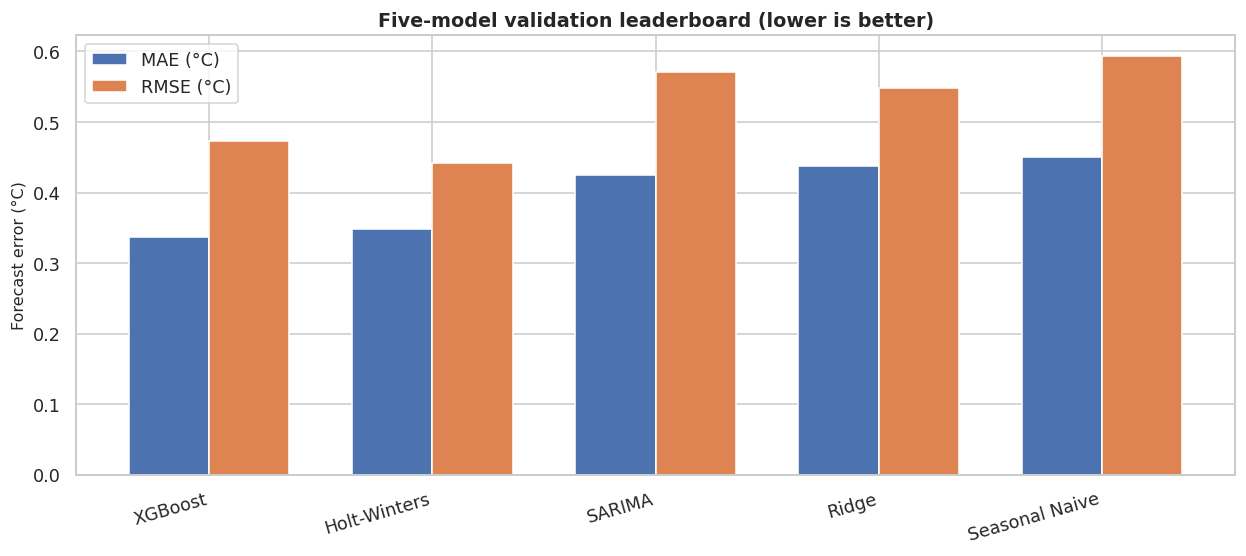

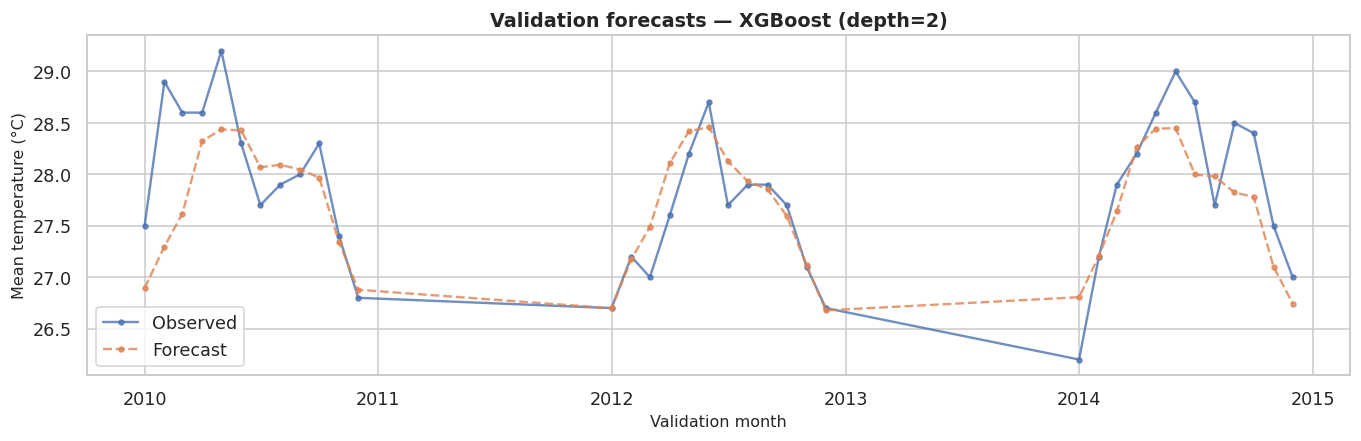

In [25]:
fig, ax = plt.subplots(figsize=(11,5))
plot_table = best_by_family.sort_values("MAE (°C)")
xx = np.arange(len(plot_table))
ax.bar(xx-0.18,plot_table["MAE (°C)"],width=0.36,label="MAE (°C)")
ax.bar(xx+0.18,plot_table["RMSE (°C)"],width=0.36,label="RMSE (°C)")
ax.set_xticks(xx,plot_table.Model,rotation=16,ha="right")
ax.set(title="Five-model validation leaderboard (lower is better)",ylabel="Forecast error (°C)")
ax.legend();fig.tight_layout();fig.savefig(FIG_DIR/"09_validation_model_leaderboard.png");plt.show()

winner_cfg = SELECTED_CONFIGS[selected_best_name]
win_df = validation_predictions.query("model == @selected_best_name and configuration == @winner_cfg").sort_values("month")
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(win_df.month,win_df.actual_C,"o-",markersize=3,label="Observed",alpha=.8)
ax.plot(win_df.month,win_df.predicted_C,"o--",markersize=3,label="Forecast",alpha=.8)
ax.set(title=f"Validation forecasts — {selected_best_name} ({winner_cfg})",xlabel="Validation month",ylabel="Mean temperature (°C)")
ax.legend();fig.tight_layout();fig.savefig(FIG_DIR/"10_validation_winner_actual_vs_predicted.png");plt.show()


### Export reproducible results and conclusions

The outputs include individual forecast values, all tested configurations, and the best validated member of each model family. **Model diagnostics and further controlled improvement are reserved for validation and refinement**, and the untouched test years remain for final evaluation.

**Resume reporting rule:** cite an independently evaluated test MAE/RMSE only after final evaluation. A validation improvement can be described as validation performance, not as final generalization performance.

In [26]:
full_evaluation.to_csv(output_dir/"m4_candidate_evaluation_matrix.csv",index=False)
best_by_family.to_csv(output_dir/"m4_model_leaderboard.csv",index=False)
validation_predictions.assign(month=validation_predictions.month.dt.strftime("%Y-%m")).to_csv(output_dir/"m4_validation_predictions.csv",index=False)
print("Saved 3 candidate evaluation CSV files to",output_dir)
print("Validation winner:",selected_best_name,"| MAE:",round(float(best_by_family.iloc[0]["MAE (°C)"]),4),"°C")
print("Final test period remains unopened: 2015-01 through 2020-06")


Saved 3 candidate evaluation CSV files to /mnt/data/Air-Temperature-Time-Series/outputs
Validation winner: XGBoost | MAE: 0.3372 °C
Final test period remains unopened: 2015-01 through 2020-06


#### Model Comparison Interpretation and Next Steps

Read the **computed evaluation matrix** above to identify the validation leader, its absolute forecast error, and how much it improves on the seasonal baseline. The final choice must remain based on validation evidence, not the visual complexity of a model.

**validation and refinement next:** (1) XGBoost feature importance and feature ablation; (2) Ridge coefficient checks; (3) SARIMA and Holt–Winters diagnostic comparisons; and (4) error behavior by calendar month. Perform those analyses strictly on the training/validation side of the cutoff before freezing configurations for final testing.

## Stage 4 — Validation and Refinement

### Model Optimization, Explainability, and Weighted Ensembles

**Research question.** Can carefully controlled model tuning or averaging improve 12-month air-temperature forecasting, and can we explain the improvements without leaking future observations?

**Precommitted safeguards:** We use the same three expanding-window origins—December 2009, 2011, and 2013—whose 12-month horizons lie entirely in **2010–2014**. We optimize **MAE (°C)**, report RMSE, signed bias and fold dispersion, and **do not access 2015–June 2020 observed temperatures**. Any apparent gains on these windows are validation gains, not independent final test results.

### Methods and why each is appropriate
1. **Ridge:** `GridSearchCV` with *explicit chronological fold indices* and only predictable calendar/trend inputs. Its normal pointwise prediction is valid for a 12-month horizon because every input is known in advance.
2. **XGBoost:** small **manual parameter grid with recursive 12-step evaluation**. Direct `GridSearchCV` would score one-step rows using true historical target lags in the validation window and give misleading multi-step performance; we do **not** use that shortcut.
3. **Feature ablation:** compare calendar-only, calendar-plus-lags, and all 11 features under identical recursive forecasting windows.
4. **Diagnostics:** assess XGBoost feature sensitivity, Ridge coefficients, SARIMA residuals, Holt-Winters variants, and month-by-month forecast error.
5. **Weighted ensemble:** average **aligned validation forecasts** from XGBoost and Holt-Winters; choose weights using validation only.

*Computational policy:* use a small fixed grid rather than optimizing hundreds of combinations against just 36 validation months.

### Leakage-safe helper for supervised and recursive forecasts

All supervised predictors must be known at a forecast origin. We train on all available historical observations, then append each next predicted temperature so that future lag and rolling features never use a held-out actual temperature. Calendar variables and `time_index` are known in advance.

In [27]:
from itertools import product
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer
from statsmodels.stats.diagnostic import acorr_ljungbox

M5_FEATURE_GROUPS = {
    "calendar_only": ["month_sin", "month_cos", "time_index"],
    "calendar_plus_lags": ["month_sin", "month_cos", "time_index", "lag_1", "lag_3", "lag_6", "lag_12"],
    "all_11": FEATURE_COLUMNS,
}

def xgb_recursive_forecast(history, params, feature_set="all_11", horizon=12, neutralize=None):
    """Fit once, recursively forecast months 1..horizon using past-only features."""
    cols = M5_FEATURE_GROUPS[feature_set]
    train_x = make_temperature_features(history).assign(y=history).dropna(subset=cols+["y"])
    learner = XGBRegressor(objective="reg:squarederror", random_state=42,
                           n_jobs=2, colsample_bytree=0.9, subsample=0.9,
                           reg_lambda=5.0, **params)
    learner.fit(train_x[cols], train_x["y"])
    medians = train_x[cols].median()
    current = history.copy()
    future_dates = pd.date_range(history.index[-1] + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    values = []
    for dt in future_dates:
        scratch = pd.concat([current, pd.Series([np.nan], index=pd.DatetimeIndex([dt]))])
        row = make_temperature_features(scratch).loc[[dt], cols].copy()
        if neutralize is not None:
            row[neutralize] = medians[neutralize]
        if row.isna().any().any():
            raise ValueError("Recursive row contains unavailable future features")
        prediction = float(learner.predict(row)[0])
        current.loc[dt] = prediction
        values.append(prediction)
    return pd.Series(values, index=future_dates)

def m5_backtest(model, params, feature_set="all_11", neutralize=None):
    rows=[]
    for fold, origin in enumerate(VALIDATION_ORIGINS,1):
        hist=series.loc[:origin]
        if model=="XGBoost":
            pred=xgb_recursive_forecast(hist,params,feature_set,FORECAST_HORIZON,neutralize)
        else:
            pred=forecast_candidate(hist,model,params,FORECAST_HORIZON)
        assert pred.index.min()>origin and pred.index.max()<=VALID_END
        actual=validation_series.reindex(pred.index)
        assert actual.notna().all()
        for dt in pred.index:
            rows.append({"fold":fold,"month":dt,"actual_C":float(actual.loc[dt]),
                         "predicted_C":float(pred.loc[dt]),"error_C":float(pred.loc[dt]-actual.loc[dt])})
    return pd.DataFrame(rows)

def m5_summary(frame):
    metrics=forecast_metrics(frame.actual_C,frame.predicted_C)
    fold_mae=frame.groupby("fold").error_C.apply(lambda s:float(np.abs(s).mean()))
    return {**metrics,"Fold MAE SD (°C)":float(fold_mae.std(ddof=0)),
            "Worst fold MAE (°C)":float(fold_mae.max())}

assert all(d <= VALID_END for d in VALIDATION_ORIGINS)
assert VALID_END < sealed_test_dates.min()
print("The 2015–2020 test observations remain sealed.")

The 2015–2020 test observations remain sealed.


### Ridge Regression — actual `GridSearchCV` with expanding-window folds

`GridSearchCV` systematically evaluates a fixed range of regularization strengths. The indices below implement *exactly* the three previously registered 12-month validation horizons; no shuffling is used, and scaling occurs inside the pipeline for each training fold. This is valid for calendar/trend-only Ridge, because its future inputs are deterministic.

In [28]:
ridge_series=series.loc[:VALID_END]
ridge_dates=ridge_series.index
ridge_x=future_calendar_features(ridge_dates)[RIDGE_COLUMNS]
ridge_y=ridge_series.to_numpy()
ridge_splits=[]
for origin in VALIDATION_ORIGINS:
    future=pd.date_range(origin+pd.offsets.MonthBegin(1),periods=12,freq="MS")
    tr=np.flatnonzero(ridge_dates<=origin)
    va=np.flatnonzero(ridge_dates.isin(future))
    assert len(va)==12 and len(tr)>=336 and np.max(tr)<np.min(va)
    ridge_splits.append((tr,va))

ridge_grid=GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    param_grid={"ridge__alpha":[0.01,0.1,1.0,10.0,100.0]},
    scoring="neg_mean_absolute_error", cv=ridge_splits,
    n_jobs=1, refit=False, return_train_score=False
)
ridge_grid.fit(ridge_x,ridge_y)
ridge_table=pd.DataFrame(ridge_grid.cv_results_)[["param_ridge__alpha","mean_test_score","std_test_score","rank_test_score"]]
ridge_table["Validation fold-mean MAE (°C)"]=-ridge_table["mean_test_score"]
ridge_table=ridge_table.sort_values("rank_test_score")
RIDGE_BEST_ALPHA=float(ridge_grid.best_params_["ridge__alpha"])
print("Ridge GridSearchCV winner: alpha =",RIDGE_BEST_ALPHA)
display(ridge_table[["param_ridge__alpha","Validation fold-mean MAE (°C)","std_test_score"]].round(4))
ridge_table.to_csv(output_dir/"m5_ridge_gridsearch.csv",index=False)

Ridge GridSearchCV winner: alpha = 10.0


,param_ridge__alpha,Validation fold-mean MAE (°C),std_test_score
3,10.00,0.4382,0.0757
2,1.00,0.4406,0.0794
4,100.00,0.4407,0.0573
1,0.10,0.4409,0.0798
0,0.01,0.4409,0.0798


### XGBoost — recursive horizon-aligned hyperparameter grid

For XGBoost, a standard `GridSearchCV` cannot directly judge our recursive 12-month task: lagged feature rows in its test split would incorporate actual temperatures from previous held-out months. Instead, each candidate is evaluated by forecasting the full 12-month horizon recursively, exactly as in final deployment. This is a **time-series-aware grid search**, not a claim to have used sklearn's `GridSearchCV` for XGBoost.

In [29]:
xgb_options=[
    {"n_estimators":n,"max_depth":depth,"learning_rate":rate}
    for n,depth,rate in product((120,240),(2,3),(0.03,0.07))
]
xgb_trials=[]
for params in xgb_options:
    start=time.perf_counter()
    preds=m5_backtest("XGBoost",params,"all_11")
    xgb_trials.append({**params,**m5_summary(preds),"Runtime (s)":time.perf_counter()-start})
xgb_search=pd.DataFrame(xgb_trials).sort_values("MAE (°C)").reset_index(drop=True)
XGB_BEST_PARAMS={k:(int(xgb_search.iloc[0][k]) if k in ("n_estimators","max_depth") else float(xgb_search.iloc[0][k]))
                 for k in ("n_estimators","max_depth","learning_rate")}
print("Best recursive XGBoost parameters:",XGB_BEST_PARAMS)
display(xgb_search.round(4))
xgb_search.to_csv(output_dir/"m5_xgboost_recursive_grid.csv",index=False)

Best recursive XGBoost parameters: {'n_estimators': 240, 'max_depth': 3, 'learning_rate': 0.07}


,n_estimators,max_depth,learning_rate,MAE (°C),RMSE (°C),Bias (°C),Fold MAE SD (°C),Worst fold MAE (°C),Runtime (s)
0,240,3,0.07,0.3369,0.4547,-0.1487,0.1223,0.4719,0.3835
1,120,3,0.07,0.3393,0.4587,-0.1594,0.1208,0.4580,0.2681
2,120,2,0.07,0.3406,0.4655,-0.1428,0.1117,0.4436,0.2531
3,240,2,0.03,0.3427,0.4793,-0.1252,0.1148,0.4656,0.2998
4,120,3,0.03,0.3453,0.4797,-0.1838,0.1272,0.4733,0.2676
5,240,3,0.03,0.3461,0.4667,-0.1732,0.1279,0.4650,0.3346
6,120,2,0.03,0.3608,0.5033,-0.1783,0.1202,0.4847,0.2600
7,240,2,0.07,0.3646,0.4728,-0.1534,0.1329,0.4717,0.3054


### XGBoost feature ablation — are all eleven inputs helpful?

The feature groups are **calendar/trend only**, **calendar/trend + four lags**, and the complete **11-feature** set (lags and shifted rolling statistics). Every variant uses the same validation dates and the tuned model parameters. We choose the feature subset on validation MAE; the untouched test set cannot influence this choice.

Validation-selected XGBoost feature group: calendar_plus_lags


,Feature set,Number of features,MAE (°C),RMSE (°C),Bias (°C),Fold MAE SD (°C),Worst fold MAE (°C)
0,calendar_plus_lags,7,0.3287,0.4338,-0.1464,0.1194,0.4500
1,all_11,11,0.3369,0.4547,-0.1487,0.1223,0.4719
2,calendar_only,3,0.3381,0.4370,-0.1065,0.1109,0.4287


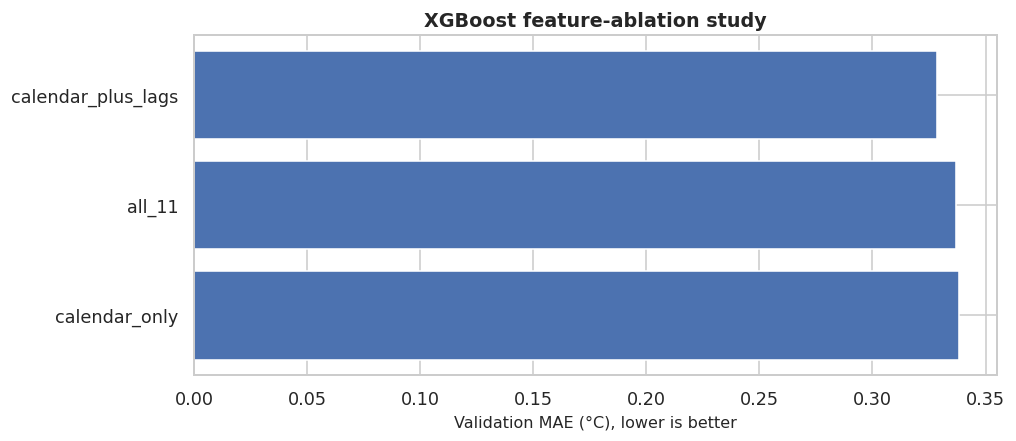

In [30]:
ablation_rows=[]
ablation_predictions={}
for name in M5_FEATURE_GROUPS:
    preds=m5_backtest("XGBoost",XGB_BEST_PARAMS,name)
    ablation_predictions[name]=preds
    ablation_rows.append({"Feature set":name,"Number of features":len(M5_FEATURE_GROUPS[name]),**m5_summary(preds)})
ablation_table=pd.DataFrame(ablation_rows).sort_values("MAE (°C)").reset_index(drop=True)
XGB_BEST_FEATURE_SET=str(ablation_table.iloc[0]["Feature set"])
print("Validation-selected XGBoost feature group:",XGB_BEST_FEATURE_SET)
display(ablation_table.round(4))
ablation_table.to_csv(output_dir/"m5_feature_ablation.csv",index=False)
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(ablation_table["Feature set"],ablation_table["MAE (°C)"])
ax.invert_yaxis();ax.set(xlabel="Validation MAE (°C), lower is better",title="XGBoost feature-ablation study")
fig.tight_layout();fig.savefig(output_dir/"m5_feature_ablation.png",dpi=150);plt.show()

### Feature importance — model usage and forecast sensitivity

Tree *gain importance* quantifies how much the fitted trees use each input for split improvement; it is **not a causal statement**. To test forecast sensitivity, we additionally replace each input with its training median before predicting, repeating the same recursive validation windows. Changes in MAE may be negative, particularly when features are correlated; this diagnostic is not standard permutation importance.

,feature,tree_importance,MAE change when neutralized (°C)
1,month_cos,0.34638,0.09763
3,lag_1,0.24416,0.06189
6,lag_12,0.19556,0.05997
0,month_sin,0.10448,0.07278
2,time_index,0.04829,0.08527
4,lag_3,0.03362,0.02696
5,lag_6,0.02752,0.02793


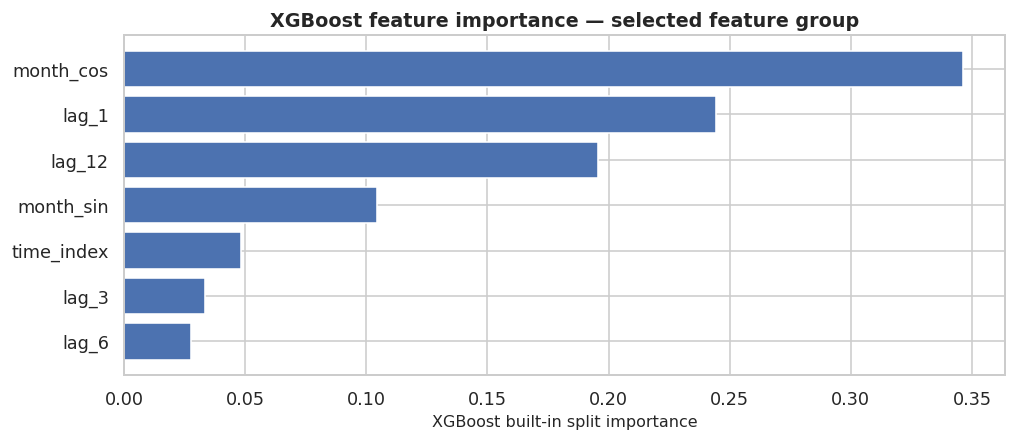

In [31]:
selected_cols=M5_FEATURE_GROUPS[XGB_BEST_FEATURE_SET]
x_train=make_temperature_features(train_series).assign(y=train_series).dropna(subset=selected_cols+["y"])
importance_estimator=XGBRegressor(objective="reg:squarederror",random_state=42,
    n_jobs=2,colsample_bytree=0.9,subsample=0.9,reg_lambda=5.0,**XGB_BEST_PARAMS)
importance_estimator.fit(x_train[selected_cols],x_train.y)
importance_table=pd.DataFrame({"feature":selected_cols,"tree_importance":importance_estimator.feature_importances_})
reference_mae=m5_summary(ablation_predictions[XGB_BEST_FEATURE_SET])["MAE (°C)"]
sensitivity=[]
for col in selected_cols:
    altered=m5_backtest("XGBoost",XGB_BEST_PARAMS,XGB_BEST_FEATURE_SET,neutralize=col)
    sensitivity.append({"feature":col,"MAE change when neutralized (°C)":m5_summary(altered)["MAE (°C)"]-reference_mae})
importance_table=importance_table.merge(pd.DataFrame(sensitivity),on="feature").sort_values("tree_importance",ascending=False)
display(importance_table.round(5))
importance_table.to_csv(output_dir/"m5_xgboost_feature_importance.csv",index=False)
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(importance_table.feature,importance_table.tree_importance)
ax.invert_yaxis();ax.set(xlabel="XGBoost built-in split importance",title="XGBoost feature importance — selected feature group")
fig.tight_layout();fig.savefig(output_dir/"m5_xgb_importance.png",dpi=150);plt.show()

### Ridge coefficient interpretation

Ridge is linear in its standardized inputs. The coefficient signs show associations with predicted temperature after accounting for the other calendar/trend terms, not causal drivers. Coefficients are expressed per one training-standard-deviation change in the corresponding feature.

In [32]:
ridge_interpret=make_pipeline(StandardScaler(),Ridge(alpha=RIDGE_BEST_ALPHA))
ridge_interpret.fit(future_calendar_features(train_series.index)[RIDGE_COLUMNS],train_series)
ridge_coef=pd.DataFrame({"feature":RIDGE_COLUMNS,"coefficient_per_SD":ridge_interpret.named_steps["ridge"].coef_})
display(ridge_coef.round(5))
ridge_coef.to_csv(output_dir/"m5_ridge_coefficients.csv",index=False)

,feature,coefficient_per_SD
0,month_sin,-0.04747
1,month_cos,-0.54735
2,time_index,0.20897


### SARIMA diagnostics and Holt-Winters configuration comparison

SARIMA diagnostics use the **validation-selected** SARIMA configuration on data through **December 2014**. We examine residual autocorrelation with Ljung–Box tests at 12 and 24 lags, and report AIC as a within-family fit diagnostic—not an equivalent replacement for forecast validation. Holt-Winters tests three small trend configurations on the original validation origins; the ranking remains based on MAE.

Validation-selected SARIMA: (1,0,0)(1,0,0)[12] AIC: 551.62


,lb_stat,lb_pvalue
12,28.852781,4.143146e-03
24,76.140236,2.476398e-07


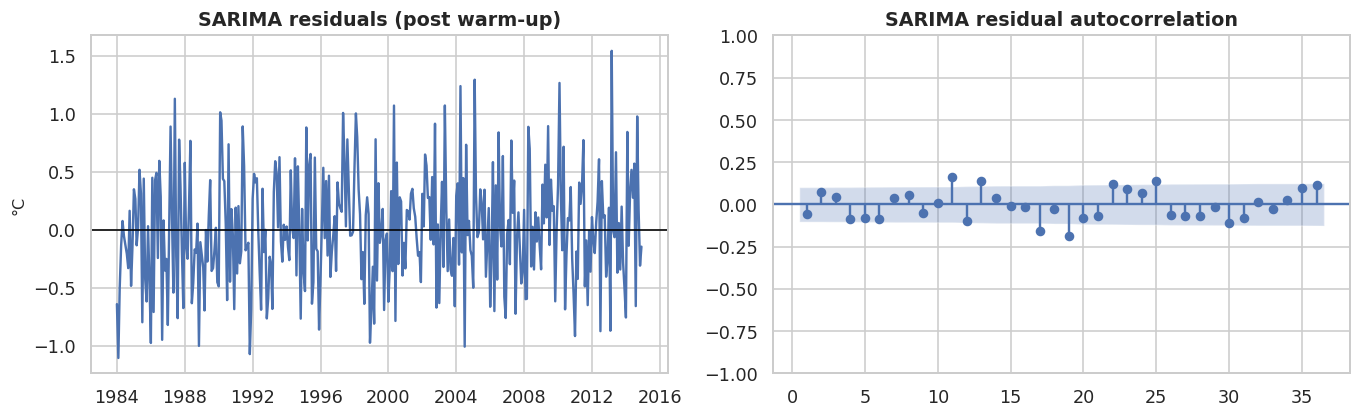

,Configuration,MAE (°C),RMSE (°C),Bias (°C),Fold MAE SD (°C),Worst fold MAE (°C)
0,additive-trend,0.3480,0.4418,-0.0890,0.1030,0.4256
1,damped-trend,0.3484,0.4428,-0.1030,0.1022,0.4234
2,no-trend,0.3487,0.4433,-0.1034,0.1022,0.4226


In [33]:
sarima_label=SELECTED_CONFIGS["SARIMA"]
sarima_params=MODEL_CANDIDATES["SARIMA"][sarima_label]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sarima_fit=SARIMAX(series.loc[:VALID_END],order=sarima_params["order"],
           seasonal_order=sarima_params["seasonal_order"],trend="c",
           enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=75)
resid=pd.Series(sarima_fit.resid,index=series.loc[:VALID_END].index).iloc[24:]
ljung=acorr_ljungbox(resid,lags=[12,24],return_df=True)
print("Validation-selected SARIMA:",sarima_label,"AIC:",round(sarima_fit.aic,2))
display(ljung)
ljung.to_csv(output_dir/"m5_sarima_ljungbox.csv")
fig,ax=plt.subplots(1,2,figsize=(12,3.8))
ax[0].plot(resid.index,resid);ax[0].axhline(0,color="black",lw=1);ax[0].set(title="SARIMA residuals (post warm-up)",ylabel="°C")
plot_acf(resid,lags=36,ax=ax[1],zero=False);ax[1].set(title="SARIMA residual autocorrelation")
fig.tight_layout();fig.savefig(output_dir/"m5_sarima_residuals.png",dpi=150);plt.show()

hw_variants={"no-trend":{"trend":None},"additive-trend":{"trend":"add"},
             "damped-trend":{"trend":"add","damped_trend":True}}
def hw_variant_predict(history,params):
    args={"trend":params["trend"],"seasonal":"add","seasonal_periods":12,
          "initialization_method":"estimated"}
    if params.get("damped_trend"): args["damped_trend"]=True
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted=ExponentialSmoothing(history,**args).fit(optimized=True)
    dates=pd.date_range(history.index[-1]+pd.offsets.MonthBegin(1),periods=12,freq="MS")
    return pd.Series(fitted.forecast(12).to_numpy(),index=dates)
hw_reports=[];hw_saved={}
for name,params in hw_variants.items():
    parts=[]
    for fold,origin in enumerate(VALIDATION_ORIGINS,1):
        pred=hw_variant_predict(series.loc[:origin],params)
        observed=validation_series.loc[pred.index]
        parts.extend({"fold":fold,"month":dt,"actual_C":float(observed.loc[dt]),
                      "predicted_C":float(pred.loc[dt]),"error_C":float(pred.loc[dt]-observed.loc[dt])} for dt in pred.index)
    frame=pd.DataFrame(parts); hw_saved[name]=frame
    hw_reports.append({"Configuration":name,**m5_summary(frame)})
hw_table=pd.DataFrame(hw_reports).sort_values("MAE (°C)").reset_index(drop=True)
HW_BEST_VARIANT=str(hw_table.iloc[0]["Configuration"])
display(hw_table.round(4));hw_table.to_csv(output_dir/"m5_holtwinters_comparison.csv",index=False)

### Weighted forecast ensemble — can averaging reduce error?

We combine the **validation-selected** XGBoost feature configuration with the best Holt-Winters variant. For a weight $w$, the ensemble prediction is $w \hat{y}_{XGB} + (1-w) \hat{y}_{HW}$. We test a **small predeclared grid** of weights (0, .25, .50, .75, 1), including individual models as endpoints. All records are joined by the exact `(fold, month)` key, and no held-out test labels are accessed.

With only 36 validation points, small improvements could reflect validation noise; we will carry the winner into final testing without changing weights after seeing test results.

Best validation-only XGB weight: 1.0


,XGBoost weight,Holt-Winters weight,MAE (°C),RMSE (°C),Bias (°C),Fold MAE SD (°C),Worst fold MAE (°C)
0,1.00,0.00,0.3287,0.4338,-0.1464,0.1194,0.4500
1,0.75,0.25,0.3296,0.4282,-0.1320,0.1190,0.4405
2,0.50,0.50,0.3336,0.4277,-0.1177,0.1150,0.4311
3,0.25,0.75,0.3394,0.4323,-0.1033,0.1096,0.4219
4,0.00,1.00,0.3480,0.4418,-0.0890,0.1030,0.4256


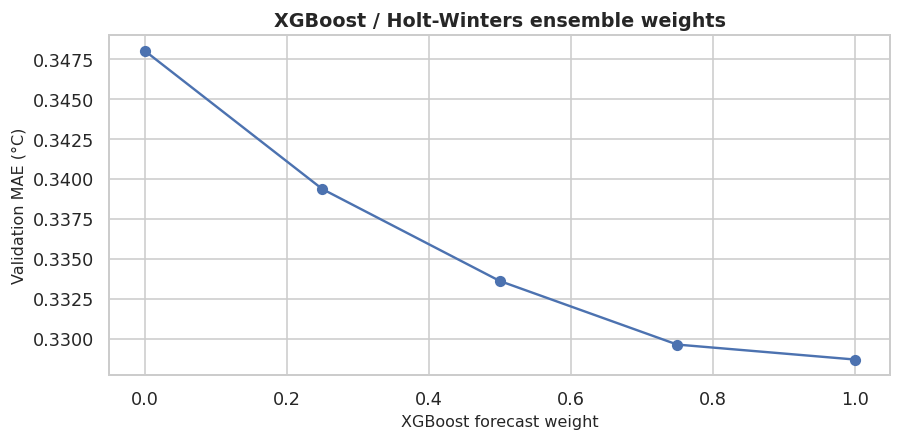

In [34]:
ensemble_xgb=ablation_predictions[XGB_BEST_FEATURE_SET]
ensemble_hw=hw_saved[HW_BEST_VARIANT]
aligned=ensemble_xgb.merge(ensemble_hw,on=["fold","month"],suffixes=("_xgb","_hw"),validate="one_to_one")
assert len(aligned)==36 and np.allclose(aligned.actual_C_xgb,aligned.actual_C_hw)
assert aligned.month.max()<=VALID_END and aligned.month.min()>TRAIN_END
ensemble_rows=[];ensemble_candidates={}
for w in (0.0,0.25,0.50,0.75,1.0):
    pred=w*aligned.predicted_C_xgb+(1-w)*aligned.predicted_C_hw
    frame=pd.DataFrame({"fold":aligned.fold,"month":aligned.month,
        "actual_C":aligned.actual_C_xgb,"predicted_C":pred,"error_C":pred-aligned.actual_C_xgb})
    ensemble_candidates[w]=frame
    ensemble_rows.append({"XGBoost weight":w,"Holt-Winters weight":1-w,**m5_summary(frame)})
ensemble_table=pd.DataFrame(ensemble_rows).sort_values("MAE (°C)").reset_index(drop=True)
BEST_WEIGHT=float(ensemble_table.iloc[0]["XGBoost weight"])
print("Best validation-only XGB weight:",BEST_WEIGHT)
display(ensemble_table.round(4))
ensemble_table.to_csv(output_dir/"m5_weighted_ensemble_search.csv",index=False)
ensemble_candidates[BEST_WEIGHT].to_csv(output_dir/"m5_selected_ensemble_validation_predictions.csv",index=False)
fig,ax=plt.subplots(figsize=(8,4));ax.plot(ensemble_table.sort_values("XGBoost weight")["XGBoost weight"],
  ensemble_table.sort_values("XGBoost weight")["MAE (°C)"],marker="o")
ax.set(xlabel="XGBoost forecast weight",ylabel="Validation MAE (°C)",title="XGBoost / Holt-Winters ensemble weights")
fig.tight_layout();fig.savefig(output_dir/"m5_ensemble_weights.png",dpi=150);plt.show()

### Calendar-month error analysis and final validation leaderboard

Month-level MAE reveals where models struggle despite similar aggregate scores. Because our windows cover only three years, month-wise estimates are based on three errors per month and should not be overinterpreted. The final leaderboard includes **all five individual families plus the ensemble**, with MAE, RMSE, signed bias, fold consistency and baseline improvement.

,Model,MAE (°C),RMSE (°C),Bias (°C),Fold MAE SD (°C),Worst fold MAE (°C),Improvement vs baseline (%)
0,Weighted Ensemble,0.3287,0.4338,-0.1464,0.1194,0.4500,26.9578
1,XGBoost,0.3287,0.4338,-0.1464,0.1194,0.4500,26.9578
2,Holt-Winters,0.3480,0.4418,-0.0890,0.1030,0.4256,22.6641
3,SARIMA,0.4246,0.5712,-0.2579,0.1210,0.5108,5.6398
4,Ridge,0.4382,0.5516,0.0818,0.0757,0.5348,2.6232
5,Seasonal Naive,0.4500,0.5930,-0.1333,0.1389,0.5833,0.0000


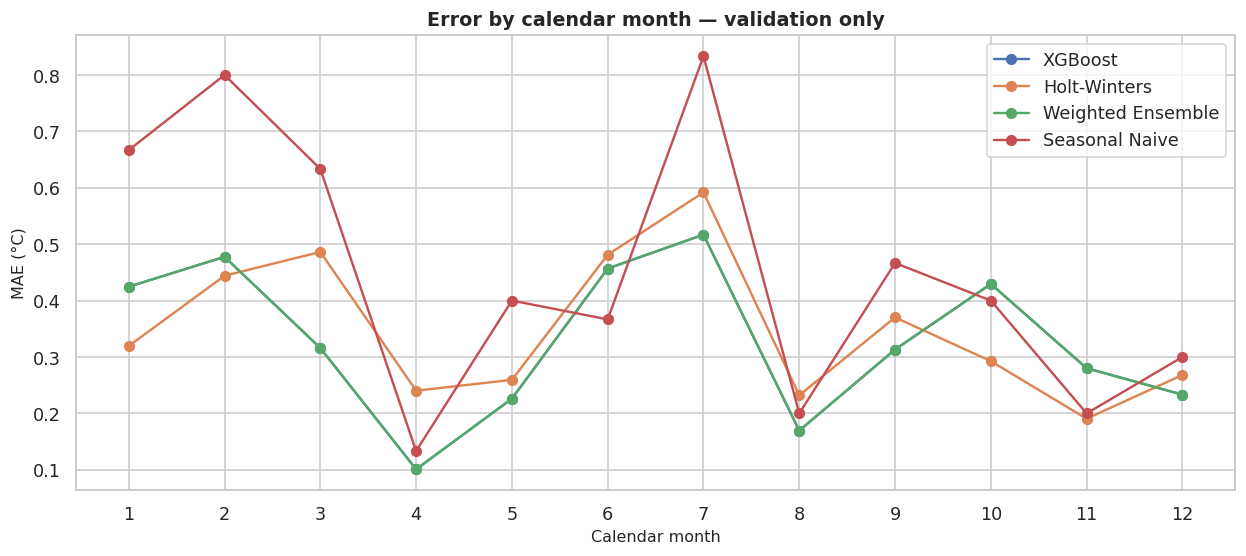

In [35]:
selected_frames={}
for model in ("Seasonal Naive","Ridge","SARIMA"):
    if model=="Ridge":
        selected_frames[model]=m5_backtest("Ridge",{"alpha":RIDGE_BEST_ALPHA})
    else:
        chosen=SELECTED_CONFIGS[model]
        selected_frames[model]=m5_backtest(model,MODEL_CANDIDATES[model][chosen])
selected_frames["Holt-Winters"]=hw_saved[HW_BEST_VARIANT]
selected_frames["XGBoost"]=ensemble_xgb
selected_frames["Weighted Ensemble"]=ensemble_candidates[BEST_WEIGHT]
report=[];months=[]
base=m5_summary(selected_frames["Seasonal Naive"])["MAE (°C)"]
for name,frame in selected_frames.items():
    met=m5_summary(frame)
    report.append({"Model":name,**met,"Improvement vs baseline (%)":100*(base-met["MAE (°C)"])/base})
    for month,g in frame.groupby(frame.month.dt.month):
        months.append({"Model":name,"Calendar month":int(month),"MAE (°C)":float(g.error_C.abs().mean()),
                       "Bias (°C)":float(g.error_C.mean()),"Samples":len(g)})
leaderboard_m5=pd.DataFrame(report).sort_values("MAE (°C)").reset_index(drop=True)
monthly_errors_m5=pd.DataFrame(months)
display(leaderboard_m5.round(4))
leaderboard_m5.to_csv(output_dir/"m5_final_validation_leaderboard.csv",index=False)
monthly_errors_m5.to_csv(output_dir/"m5_monthly_error_analysis.csv",index=False)
fig,ax=plt.subplots(figsize=(11,5))
for name in ("XGBoost","Holt-Winters","Weighted Ensemble","Seasonal Naive"):
    g=monthly_errors_m5.loc[monthly_errors_m5.Model==name]
    ax.plot(g["Calendar month"],g["MAE (°C)"],marker="o",label=name)
ax.set_xticks(range(1,13));ax.set(xlabel="Calendar month",ylabel="MAE (°C)",title="Error by calendar month — validation only")
ax.legend();fig.tight_layout();fig.savefig(output_dir/"m5_monthly_errors.png",dpi=150);plt.show()
assert all(frame.month.max()<=VALID_END for frame in selected_frames.values())
assert sealed_test_dates.min()>VALID_END

#### Refinement Findings, Limitations, and Frozen Decisions

**How to read the results.** The displayed comparison tables are computed from historical validation predictions. The lowest *validation* MAE is a provisional choice, **not** a held-out test claim. Our evaluation matrix also includes RMSE (penalizes large misses), signed bias (systematic over/under-forecasting), and fold-to-fold variation (stability). The feature-importance diagnostics measure dependence or split use, not causation.

**Selection policy for final evaluation:** Freeze each individual's tuned parameters and feature group, plus the selected ensemble weights, **before** evaluating January 2015–June 2020. If weighted averaging performs worse, say so explicitly. We will select the leading *validation* approach for the final July 2020–June 2021 historical projection and make resume statements from **held-out test** metrics, not training or search scores.

**Limitations:** 36 validation forecast months are modest; candidate ranking can be sensitive to individual hot/cool years. Our three validation origins use nonoverlapping 12-month targets, but subsequent fold training includes intervening observations. Repeating experimentation on the same validation windows risks selection overfitting; avoid expanding the search after viewing these results.

**Important selection clarification:** If the ensemble weight search chooses XGBoost weight **1.00**, it is **identical to XGBoost alone** and is reported as XGBoost, not as an ensemble performance gain. An equal-weight blend can be better on RMSE while worse on our predeclared primary metric (MAE).

In [36]:
M5_FROZEN_CONFIG={
    "xgb_params":XGB_BEST_PARAMS.copy(),
    "xgb_feature_group":XGB_BEST_FEATURE_SET,
    "ridge_alpha":RIDGE_BEST_ALPHA,
    "holtwinters_variant":HW_BEST_VARIANT,
    "sarima_configuration":SELECTED_CONFIGS["SARIMA"],
    "ensemble_xgb_weight":BEST_WEIGHT,
    "validation_selected_model":("XGBoost" if BEST_WEIGHT==1.0 else "Holt-Winters" if BEST_WEIGHT==0.0 else "Weighted Ensemble"),
    "validation_last_month":"2014-12",
    "test_start_month":"2015-01",
}
import json
with open(output_dir/"m5_frozen_configuration.json","w",encoding="utf-8") as f:
    json.dump(M5_FROZEN_CONFIG,f,indent=2)
print("Frozen before final testing:")
print(json.dumps(M5_FROZEN_CONFIG,indent=2))

Frozen before final testing:
{
  "xgb_params": {
    "n_estimators": 240,
    "max_depth": 3,
    "learning_rate": 0.07
  },
  "xgb_feature_group": "calendar_plus_lags",
  "ridge_alpha": 10.0,
  "holtwinters_variant": "additive-trend",
  "sarima_configuration": "(1,0,0)(1,0,0)[12]",
  "ensemble_xgb_weight": 1.0,
  "validation_selected_model": "XGBoost",
  "validation_last_month": "2014-12",
  "test_start_month": "2015-01"
}


## Stage 5 — Final Out-of-Sample Evaluation

**Objective.** Assess the model choices frozen in validation and refinement on observations never consulted for selecting features, hyperparameters, models or ensemble weights. Then refit the validation-selected approach on all available history and produce a **historical** 12-month projection for July 2020–June 2021.

**Important distinction:** This is a retrospective forecast from the dataset's June 2020 cutoff, **not** a forecast of present-day temperatures. A holdout score is a measure of predictive error, not a classification accuracy percentage. All error metrics are expressed in degrees Celsius.

### Research protocol

1. Load the frozen parameters and verify that the test period starts strictly after the validation period.
2. Evaluate fixed model configurations on consecutive 12-month forecast horizons beginning in 2015, 2016, 2017, 2018 and 2019, followed by the available six months in 2020.
3. Refit on actual historical observations available at each forecast origin; models **never** use observed future temperatures inside the forecast horizon.
4. Compare MAE (primary), RMSE, signed bias, baseline improvement and fold consistency.
5. Refit the validation-selected model on all data through June 2020 for the final 12-month historical projection.

The holdout test is not used to alter any selected configuration.

### Frozen configurations and test schedule

Six non-overlapping origin dates ensure that **every one of the 66 held-out months** is assessed exactly once. Each origin is followed by a forecast horizon of up to 12 months. The final half-year is only six months long because the source data end in June 2020. A fresh fit at each origin is allowed because at that point the preceding observed months would have been available to a real forecaster.

In [37]:
import json
from pathlib import Path
with open(output_dir / "m5_frozen_configuration.json", encoding="utf-8") as fh:
    frozen_m6 = json.load(fh)
assert frozen_m6["validation_last_month"] == "2014-12"
assert frozen_m6["test_start_month"] == "2015-01"
TEST_ORIGINS = pd.to_datetime(["2014-12-01", "2015-12-01", "2016-12-01", "2017-12-01", "2018-12-01", "2019-12-01"])
test_index = series.loc["2015-01":"2020-06"].index
assert len(test_index) == 66
schedule = []
for i, origin in enumerate(TEST_ORIGINS, 1):
    future = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=12, freq="MS")
    future = future[future <= pd.Timestamp("2020-06-01")]
    schedule.append({"Fold": i, "History through": origin.strftime("%Y-%m"), "Forecast start": future.min().strftime("%Y-%m"), "Forecast end": future.max().strftime("%Y-%m"), "Horizon": len(future)})
assert sum(row["Horizon"] for row in schedule) == len(test_index)
display(pd.DataFrame(schedule))
print("Frozen validation-selected approach:", frozen_m6["validation_selected_model"])

,Fold,History through,Forecast start,Forecast end,Horizon
0,1,2014-12,2015-01,2015-12,12
1,2,2015-12,2016-01,2016-12,12
2,3,2016-12,2017-01,2017-12,12
3,4,2017-12,2018-01,2018-12,12
4,5,2018-12,2019-01,2019-12,12
5,6,2019-12,2020-01,2020-06,6


Frozen validation-selected approach: XGBoost


### Forecast each held-out window with every frozen model

The model families retain their preselected settings: Seasonal Naive, Ridge with validation-selected regularization, Holt-Winters with its chosen trend configuration, SARIMA with its selected seasonal order, XGBoost with its tuned hyperparameters and selected feature group, and the validation-selected fixed-weight ensemble. **No search or retuning is permitted here.**

For the last origin, the forecast horizon is six months. Note that using the observations from preceding test years as model training history for later origins is *walk-forward evaluation*, not test leakage: those observations are already historical at that origin. The final scores still provide just one post-selection assessment, and should not be mined for another round of model selection.

In [38]:
def m6_forecast(history, name, horizon):
    if name == "Seasonal Naive":
        return forecast_candidate(history, name, {}, horizon)
    if name == "Ridge":
        return forecast_candidate(history, name, {"alpha": float(frozen_m6["ridge_alpha"])}, horizon)
    if name == "Holt-Winters":
        return hw_variant_predict_horizon(history, hw_variants[frozen_m6["holtwinters_variant"]], horizon)
    if name == "SARIMA":
        cfg = MODEL_CANDIDATES["SARIMA"][frozen_m6["sarima_configuration"]]
        return forecast_candidate(history, name, cfg, horizon)
    if name == "XGBoost":
        return xgb_recursive_forecast(history, frozen_m6["xgb_params"], frozen_m6["xgb_feature_group"], horizon)
    if name == "Weighted Ensemble":
        w = float(frozen_m6["ensemble_xgb_weight"])
        if w == 1.0: return m6_forecast(history, "XGBoost", horizon)
        if w == 0.0: return m6_forecast(history, "Holt-Winters", horizon)
        return w*m6_forecast(history, "XGBoost", horizon) + (1-w)*m6_forecast(history, "Holt-Winters", horizon)
    raise ValueError(name)

def hw_variant_predict_horizon(history, params, horizon):
    args = {"trend": params["trend"], "seasonal": "add", "seasonal_periods": 12, "initialization_method": "estimated"}
    if params.get("damped_trend"):
        args["damped_trend"] = True
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = ExponentialSmoothing(history, **args).fit(optimized=True)
    dates = pd.date_range(history.index[-1] + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    return pd.Series(fit.forecast(horizon).to_numpy(), index=dates)

model_names_m6 = ["Seasonal Naive", "Ridge", "Holt-Winters", "SARIMA", "XGBoost", "Weighted Ensemble"]
test_rows_m6 = []
for fold, origin in enumerate(TEST_ORIGINS, 1):
    history = series.loc[:origin].copy()
    end = min(origin + pd.DateOffset(months=12), pd.Timestamp("2020-06-01"))
    actual = series.loc[origin + pd.offsets.MonthBegin(1):end]
    assert len(actual) in (6, 12)
    for name in model_names_m6:
        predictions = m6_forecast(history, name, len(actual))
        assert predictions.index.equals(actual.index)
        assert np.isfinite(predictions.to_numpy()).all()
        test_rows_m6.extend({"Model": name, "Fold": fold, "month": date, "actual_C": float(actual.loc[date]), "predicted_C": float(predictions.loc[date]), "error_C": float(predictions.loc[date] - actual.loc[date])} for date in actual.index)
    print(f"Holdout fold {fold}/6 through {origin:%Y-%m} complete")
test_predictions_m6 = pd.DataFrame(test_rows_m6)
for name in model_names_m6:
    one = test_predictions_m6.loc[test_predictions_m6.Model == name]
    assert len(one) == 66 and set(one.month) == set(test_index)
test_predictions_m6.to_csv(output_dir / "m6_test_predictions.csv", index=False)
print("Validated", len(test_predictions_m6), "held-out model-month predictions")

Holdout fold 1/6 through 2014-12 complete


Holdout fold 2/6 through 2015-12 complete


Holdout fold 3/6 through 2016-12 complete


Holdout fold 4/6 through 2017-12 complete


Holdout fold 5/6 through 2018-12 complete


Holdout fold 6/6 through 2019-12 complete
Validated 396 held-out model-month predictions


### Final evaluation matrix — MAE, RMSE, bias and baseline improvement

**MAE** is the average absolute temperature error, and is our predeclared primary criterion. **RMSE** penalizes unusually large mistakes. **Bias** reveals systematic over- or underforecasting. **Fold MAE standard deviation** describes variability over the six test windows. Baseline improvement is calculated against Seasonal Naive on exactly the same 66 months:

\[100 \times (\mathrm{MAE}_{\mathrm{baseline}}-\mathrm{MAE}_{\mathrm{model}})/\mathrm{MAE}_{\mathrm{baseline}}.\]

We will retain the original validation-selected model as the designated winner, even if a different model has the lowest test MAE. This avoids selecting a winner *after seeing* the holdout.

In [39]:
base_test = test_predictions_m6.query("Model == 'Seasonal Naive'")
base_mae = forecast_metrics(base_test.actual_C, base_test.predicted_C)["MAE (°C)"]
metrics_rows_m6 = []
for name, group in test_predictions_m6.groupby("Model", sort=False):
    metric = forecast_metrics(group.actual_C, group.predicted_C)
    by_fold = group.groupby("Fold").error_C.apply(lambda errors: errors.abs().mean())
    metrics_rows_m6.append({"Model": name, **metric,
        "Baseline improvement (%)": 100 * (base_mae - metric["MAE (°C)"]) / base_mae,
        "Fold MAE SD (°C)": float(by_fold.std(ddof=0)),
        "Worst fold MAE (°C)": float(by_fold.max()),
        "Test months": len(group)})
final_matrix_m6 = pd.DataFrame(metrics_rows_m6).sort_values("MAE (°C)").reset_index(drop=True)
final_matrix_m6.to_csv(output_dir / "m6_final_test_evaluation_matrix.csv", index=False)
display(final_matrix_m6.round(4))
validation_winner_m6 = frozen_m6["validation_selected_model"]
winner_row_m6 = final_matrix_m6.set_index("Model").loc[validation_winner_m6]
print(f"Preselected winner: {validation_winner_m6}; held-out MAE: {winner_row_m6['MAE (°C)']:.4f} °C")
print(f"Descriptive lowest-test-MAE model (not reselected): {final_matrix_m6.iloc[0]['Model']}")

,Model,MAE (°C),RMSE (°C),Bias (°C),Baseline improvement (%),Fold MAE SD (°C),Worst fold MAE (°C),Test months
0,Holt-Winters,0.4084,0.4863,0.0620,22.7640,0.1021,0.5804,66
1,Ridge,0.4337,0.5182,-0.1290,17.9766,0.0920,0.5455,66
2,Weighted Ensemble,0.4540,0.5526,-0.0534,14.1419,0.1087,0.6748,66
3,XGBoost,0.4540,0.5526,-0.0534,14.1419,0.1087,0.6748,66
4,Seasonal Naive,0.5288,0.6648,-0.0773,0.0000,0.1781,0.7167,66
5,SARIMA,0.5433,0.6322,-0.3197,-2.7530,0.1116,0.7663,66


Preselected winner: XGBoost; held-out MAE: 0.4540 °C
Descriptive lowest-test-MAE model (not reselected): Holt-Winters


### Diagnostic figures and seasonal error comparison

A model leaderboard is only a summary. We also inspect where errors arise. The first chart compares monthly holdout errors, and the second overlays actual temperatures and the **validation-selected** model's walk-forward predictions. Large misses should remain visible rather than being hidden by overall averages.

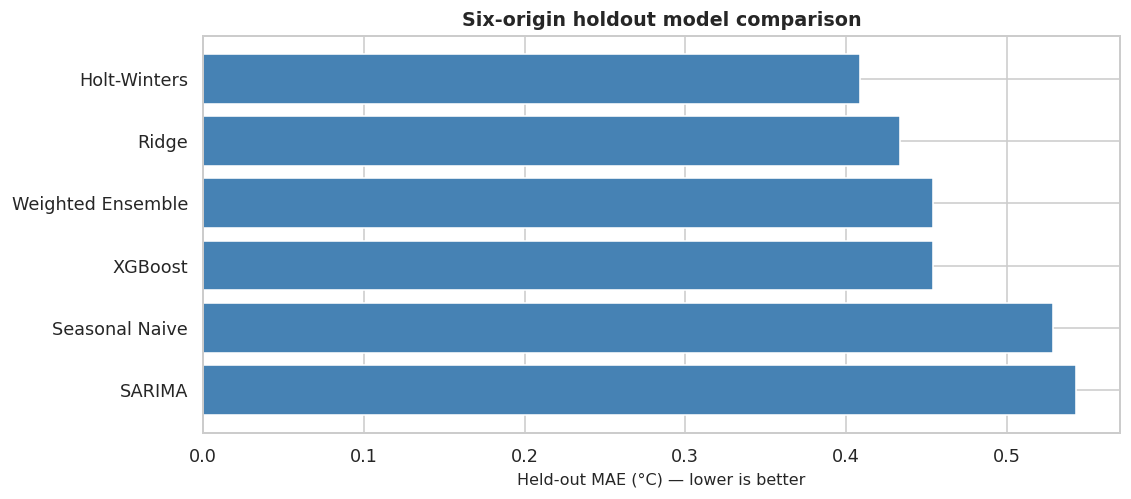

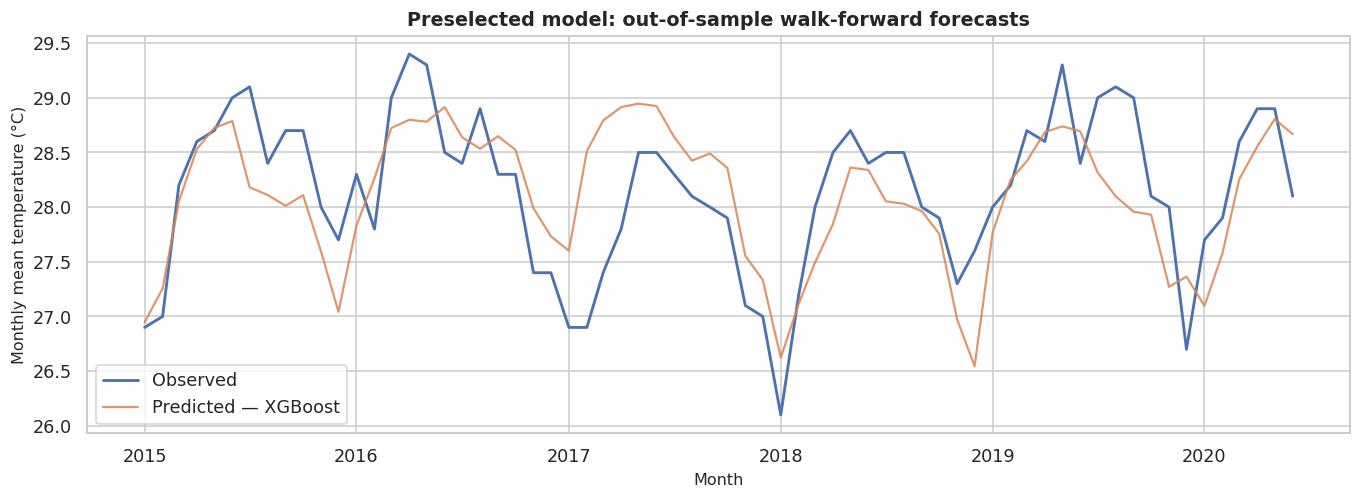

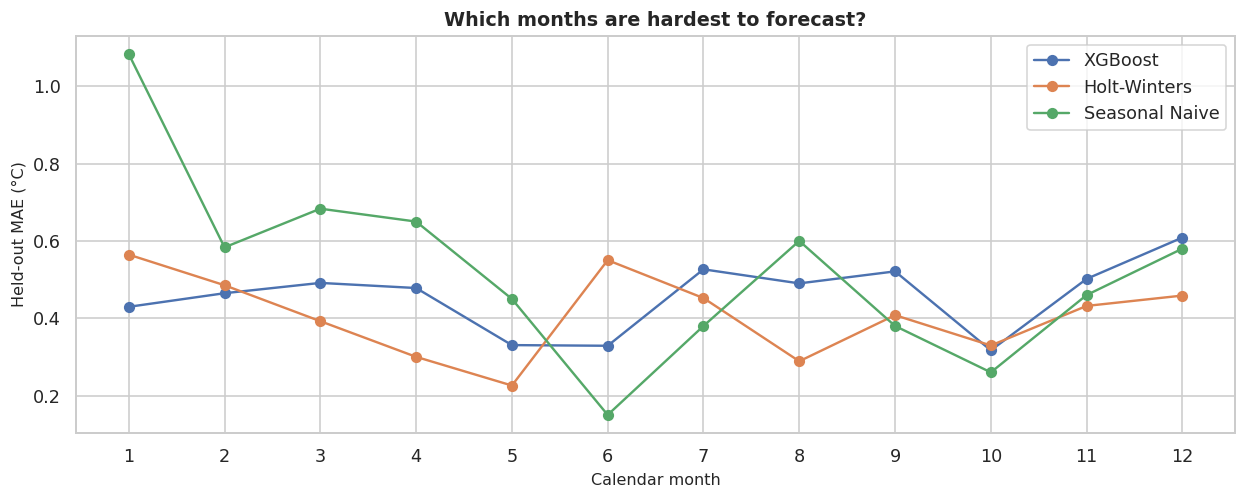

In [40]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_m6 = final_matrix_m6.sort_values("MAE (°C)", ascending=False)
ax.barh(plot_m6["Model"], plot_m6["MAE (°C)"], color="steelblue")
ax.set(xlabel="Held-out MAE (°C) — lower is better", title="Six-origin holdout model comparison")
fig.tight_layout(); fig.savefig(output_dir / "m6_test_model_comparison.png", dpi=160); plt.show()
selected_test_m6 = test_predictions_m6.loc[test_predictions_m6.Model == validation_winner_m6].sort_values("month")
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(selected_test_m6.month, selected_test_m6.actual_C, label="Observed", lw=1.8)
ax.plot(selected_test_m6.month, selected_test_m6.predicted_C, label=f"Predicted — {validation_winner_m6}", lw=1.4, alpha=.85)
ax.set(xlabel="Month", ylabel="Monthly mean temperature (°C)", title="Preselected model: out-of-sample walk-forward forecasts")
ax.legend(); fig.tight_layout(); fig.savefig(output_dir / "m6_actual_vs_predicted.png", dpi=160); plt.show()
month_error_m6 = test_predictions_m6.assign(Calendar_month=test_predictions_m6.month.dt.month).groupby(["Model", "Calendar_month"]).agg(MAE_C=("error_C", lambda v: float(v.abs().mean())), Bias_C=("error_C", "mean"), Observations=("error_C", "size")).reset_index()
month_error_m6.to_csv(output_dir / "m6_monthly_test_errors.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 4.5))
for name in [validation_winner_m6, "Holt-Winters", "Seasonal Naive"]:
    g = month_error_m6.loc[month_error_m6.Model == name]
    ax.plot(g.Calendar_month, g.MAE_C, marker="o", label=name)
ax.set(xticks=range(1, 13), xlabel="Calendar month", ylabel="Held-out MAE (°C)", title="Which months are hardest to forecast?")
ax.legend(); fig.tight_layout(); fig.savefig(output_dir / "m6_test_monthly_errors.png", dpi=160); plt.show()

## Stage 6 — Practical Output and Case Studies

### Historical Forecast Projection: July 2020 to June 2021

After evaluating the frozen models, we refit the **validation-selected** approach using all available measurements through June 2020. This is a legitimate operational refit: once the final evaluation is finished, the complete observed series is available for predicting the next 12 months. The resulting numbers are *historical backdated projections*, not today's weather forecast or verified temperatures for 2020–2021.

The forecast is a point prediction. We do **not** invent confidence or prediction intervals for the selected XGBoost/weighted model; statistically valid uncertainty quantification would require a separately calibrated interval method.

,month,forecast_mean_temp_C,model
0,2020-07,28.124,XGBoost
1,2020-08,28.117,XGBoost
2,2020-09,28.171,XGBoost
3,2020-10,27.863,XGBoost
4,2020-11,27.453,XGBoost
5,2020-12,26.942,XGBoost
6,2021-01,26.945,XGBoost
7,2021-02,27.266,XGBoost
8,2021-03,27.900,XGBoost
9,2021-04,28.476,XGBoost


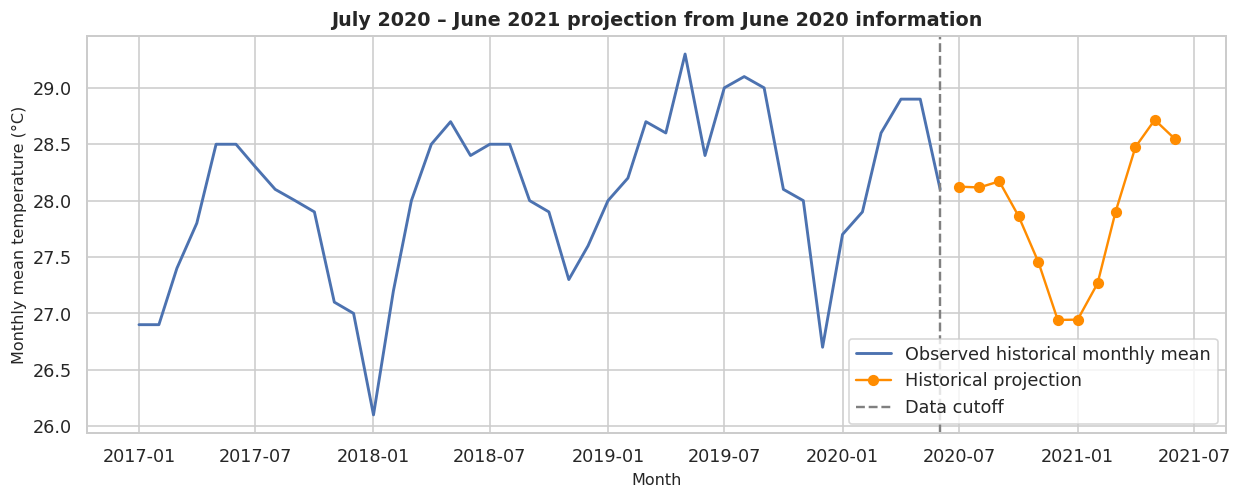

In [41]:
all_history_m6 = series.loc[:"2020-06"].copy()
assert all_history_m6.index.max() == pd.Timestamp("2020-06-01")
forecast_m6 = m6_forecast(all_history_m6, validation_winner_m6, 12)
assert len(forecast_m6) == 12
assert forecast_m6.index.min() == pd.Timestamp("2020-07-01") and forecast_m6.index.max() == pd.Timestamp("2021-06-01")
forecast_table_m6 = pd.DataFrame({"month": forecast_m6.index.strftime("%Y-%m"), "forecast_mean_temp_C": forecast_m6.to_numpy(), "model": validation_winner_m6})
forecast_table_m6.to_csv(output_dir / "m6_historical_12_month_forecast.csv", index=False)
display(forecast_table_m6.round(3))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(all_history_m6.loc["2017-01":].index, all_history_m6.loc["2017-01":].values, label="Observed historical monthly mean", lw=1.8)
ax.plot(forecast_m6.index, forecast_m6.values, marker="o", label="Historical projection", color="darkorange")
ax.axvline(pd.Timestamp("2020-06-01"), ls="--", color="grey", label="Data cutoff")
ax.set(xlabel="Month", ylabel="Monthly mean temperature (°C)", title="July 2020 – June 2021 projection from June 2020 information")
ax.legend(); fig.tight_layout(); fig.savefig(output_dir / "m6_historical_forecast.png", dpi=160); plt.show()

## Stage 7 — Project Findings

### Final Findings, Interpretation, and Limitations

**Problem solved.** We constructed a documented, reproducible workflow to forecast monthly mean surface air temperatures from the historical Changi Climate Station series, evaluated five forecasting model families plus a fixed-weight ensemble, and produced a historical 12-month projection.

**Methodology.** The analysis includes data-quality validation, statistical EDA, climatology, trend analysis, STL decomposition, time-series feature engineering, a seasonal-naive benchmark, chronological multi-origin validation, targeted tuning, ablation experiments, diagnostics and held-out walk-forward testing.

**Interpretation policy.** The final test matrix above is the evidence for generalization. The designated model was selected using pre-2015 validation data; the test set was consulted once for evaluation and not for feature/model redesign. A small error in degrees Celsius is meaningful, but does not imply a comparable percentage of classification accuracy.

**Limitations.** (1) Data end in June 2020 and do not support present-day forecasts without updates. (2) The series is univariate and excludes external climate predictors. (3) There are only 66 final test observations and six evaluation origins. (4) Recursive ML forecasts accumulate earlier forecasting errors. (5) Prediction intervals are not established for the selected model. (6) Exploratory seasonality and descriptive trend do not establish causation.

**Future work.** Refresh the observations, evaluate other stations and exogenous climate variables, expand rolling-origin evaluation, assess prediction interval coverage, and monitor forecasting drift over time. Do not tune models again on the reported holdout.

**Professional reporting.** Resume claims should quote the validation-selected model's **held-out MAE**, its improvement over Seasonal Naive and the 12-month forecast horizon—not an arbitrary 'accuracy percentage'.

In [42]:
model_name = validation_winner_m6
mae = float(winner_row_m6["MAE (°C)"])
rmse = float(winner_row_m6["RMSE (°C)"])
improvement = float(winner_row_m6["Baseline improvement (%)"])
resume_line = (f"Developed an end-to-end monthly air-temperature forecasting pipeline comparing five model families "
               f"and a weighted ensemble; the validation-selected {model_name} achieved {mae:.3f}°C MAE "
               f"and {rmse:.3f}°C RMSE across 66 held-out months "
               f"({improvement:.1f}% MAE improvement versus a seasonal-naive baseline).")
print("Verified, test-grounded resume description:\n", resume_line)
with open(output_dir / "m6_final_summary.json", "w", encoding="utf-8") as fh:
    json.dump({"validation_selected_model": model_name, "test_MAE_C": mae, "test_RMSE_C": rmse,
               "test_bias_C": float(winner_row_m6["Bias (°C)"]), "test_improvement_percent": improvement,
               "test_months": 66, "projection_start": "2020-07", "projection_end": "2021-06",
               "resume_line": resume_line}, fh, indent=2)
print("Final evaluation complete — outputs written to outputs/.")

Verified, test-grounded resume description:
 Developed an end-to-end monthly air-temperature forecasting pipeline comparing five model families and a weighted ensemble; the validation-selected XGBoost achieved 0.454°C MAE and 0.553°C RMSE across 66 held-out months (14.1% MAE improvement versus a seasonal-naive baseline).
Final evaluation complete — outputs written to outputs/.


# FINAL PROJECT REPORT
# Monthly Air Temperature Forecasting Using Machine Learning and Time-Series Analysis

---

## 1. Executive Summary

This project develops and evaluates an end-to-end time-series forecasting system to predict monthly mean air temperatures using historical climate observations from the Changi Climate Station, Singapore.

The study analyzes **462 monthly observations spanning January 1982 to June 2020**, focusing on historical temperature trends, seasonal patterns, and forecasting performance.

Five forecasting approaches were implemented:

1. Seasonal Naive Forecasting
2. Ridge Regression
3. Holt-Winters Exponential Smoothing
4. Seasonal ARIMA (SARIMA)
5. XGBoost Regressor

Additional techniques, including feature engineering, time-series cross-validation, hyperparameter optimization, feature importance analysis, feature ablation, residual diagnostics, and weighted ensemble forecasting, were incorporated to improve the reliability and interpretability of the predictions.

**Key outcome:** XGBoost achieved the lowest validation MAE of **0.3287°C**, while Holt-Winters achieved the lowest held-out test MAE of **0.4084°C**.

The results demonstrate that classical statistical forecasting methods remain highly competitive with machine learning approaches when working with relatively small, structured time-series datasets.

---

## 2. Business Problem

Accurate air temperature forecasting supports environmental monitoring, infrastructure planning, energy demand estimation, and climate-related decision-making.

However, temperature observations exhibit seasonal fluctuations, long-term variation, and short-term irregularities that complicate forecasting.

The central business problem is:

**To develop a reliable forecasting model capable of predicting future monthly mean air temperatures using historical temperature observations while accounting for seasonality, trends, and temporal dependencies.**

The project compares traditional statistical methods with machine learning techniques to determine which approaches provide the most reliable forecasts.

---

## 3. Project Objectives

The objectives of this project were to:

1. Examine historical monthly mean air temperatures and assess the quality of the dataset.
2. Identify seasonal cycles, temperature variability, and long-term trends.
3. Engineer meaningful temporal features for machine learning-based forecasting.
4. Develop multiple statistical and machine learning forecasting models.
5. Optimize selected models using appropriate time-series validation strategies.
6. Evaluate forecasting performance using multiple regression metrics.
7. Investigate model interpretability and feature contributions.
8. Assess whether weighted ensemble forecasting improves performance.
9. Generate a 12-month historical forecast and document the findings.

---

## 4. Dataset Description

The dataset contains monthly mean surface air temperature observations recorded at Changi Climate Station, Singapore.

| Attribute | Description |
|---|---|
| Dataset | Surface Air Temperature – Monthly Mean |
| Source | National Environment Agency, Singapore |
| Observation frequency | Monthly |
| Historical coverage | January 1982 – June 2020 |
| Number of observations | 462 |
| Original features | 2 |
| Forecasting target | `mean_temp` |
| Temperature unit | Degrees Celsius (°C) |
| Missing observations | 0 |
| Duplicate months | 0 |

### 4.1 Feature Description

| Feature | Data type | Description |
|---|---|---|
| `month` | Datetime | Month corresponding to the recorded observation |
| `mean_temp` | Numerical | Mean surface air temperature for the month |

### 4.2 Descriptive Statistics

| Statistic | Value |
|---|---:|
| Mean temperature | 27.67°C |
| Minimum monthly mean | 25.40°C |
| Maximum monthly mean | 29.50°C |
| Standard deviation | Approximately 0.81°C |

The dataset was found to be complete, chronologically consistent, and suitable for time-series analysis without requiring extensive missing-value imputation.

---

## 5. Data Preprocessing and Validation

The preprocessing stage focused on ensuring temporal consistency and numerical validity.

The following operations were performed:

- Converted the `month` column into the appropriate datetime format.
- Arranged observations in chronological order.
- Verified the absence of missing and duplicate observations.
- Checked continuity across the monthly timeline.
- Validated the numerical temperature column.
- Established a consistent monthly time-series index.

Because the dataset contained no missing observations, imputation was unnecessary.

**Outcome:** A clean and chronologically ordered monthly temperature dataset was prepared for exploratory analysis and forecasting.

---

## 6. Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed to understand the statistical characteristics and temporal behavior of the temperature observations.

### 6.1 Historical Temperature Distribution

The dataset exhibited relatively moderate variability in monthly mean air temperatures.

The overall average temperature was approximately **27.67°C**, with observations ranging from 25.4°C to 29.5°C.

Histograms and boxplots were used to examine the temperature distribution, spread, and unusual observations.

### 6.2 Monthly Seasonal Patterns

Monthly climatology was calculated to identify recurring seasonal patterns.

| Seasonal characteristic | Finding |
|---|---|
| Warmest month on average | May |
| Average May temperature | 28.46°C |
| Coolest month on average | December |
| Average December temperature | 26.63°C |
| Seasonal temperature difference | Approximately 1.84°C |

These findings indicate a recurring annual temperature cycle.

The seasonal variation supports incorporating calendar information and annual seasonal structure into forecasting models.

### 6.3 Long-Term Temperature Trend

Annual temperature analysis revealed an upward historical trend.

The descriptive linear trend was approximately:

**+0.236°C per decade over 1982–2019.**

This suggests that the forecasting process should consider both historical trend and recurring seasonality.

However, this descriptive relationship alone does not establish the physical causes of the observed temperature changes.

---

## 7. Seasonal Decomposition and Autocorrelation

### 7.1 STL Decomposition

Seasonal-Trend decomposition using LOESS (STL) was applied to separate the temperature series into three components:

- **Trend:** Long-term changes in the temperature level.
- **Seasonal:** Recurring annual temperature fluctuations.
- **Residual:** Variation not explained by the estimated trend and seasonality.

The analysis produced:

| Component measure | Result |
|---|---:|
| Seasonal strength | 0.759 |
| Trend strength | 0.565 |

The relatively strong seasonal component indicates that recurring annual patterns contribute substantially to historical temperature variation.

### 7.2 Autocorrelation Analysis

Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) analyses were performed to understand temporal dependencies.

Selected autocorrelation values were:

| Lag | Autocorrelation |
|---|---:|
| 1 month | 0.719 |
| 12 months | 0.635 |
| 24 months | 0.553 |

The substantial correlations at 12 and 24 months support investigating annual seasonal forecasting models.

**EDA conclusion:** Monthly mean temperature exhibits meaningful seasonality, temporal persistence, and a historical upward trend.

---

## 8. Feature Engineering

Feature engineering was performed to transform historical observations into useful predictors for machine learning models.

A total of **11 features** were constructed.

### 8.1 Calendar and Trend Features

| Feature | Purpose |
|---|---|
| `month_sin` | Encode cyclical monthly seasonality |
| `month_cos` | Encode cyclical monthly seasonality |
| `time_index` | Represent chronological progression |

Cyclical encoding preserves the relationship between December and January, which ordinary numerical month encoding does not represent effectively.

### 8.2 Lag Features

Historical temperature values were used to create:

- `lag_1`
- `lag_3`
- `lag_6`
- `lag_12`

These features provide information about earlier temperature observations.

### 8.3 Rolling Statistical Features

Additional features were constructed from prior observations:

- Three-month rolling mean
- Six-month rolling mean
- Twelve-month rolling mean
- Twelve-month rolling standard deviation

Rolling statistics capture local temperature levels, longer-term behavior, and recent variability.

All lagged and rolling features were constructed to use only historical observations available at the prediction point.

**Feature engineering outcome:** The original 336 training months produced 324 usable feature rows after accounting for the required historical window.

---

## 9. Experimental Design and Validation Strategy

A chronological splitting strategy was adopted to prevent future information from entering the training process.

| Dataset partition | Period | Observations |
|---|---|---:|
| Training | January 1982 – December 2009 | 336 |
| Validation | January 2010 – December 2014 | 60 |
| Testing | January 2015 – June 2020 | 66 |

### 9.1 Expanding-Window Validation

Three forecasting windows were used:

| Window | Historical training period | Forecast period |
|---|---|---|
| 1 | 1982–2009 | 2010 |
| 2 | 1982–2011 | 2012 |
| 3 | 1982–2013 | 2014 |

Each window generated 12 monthly predictions, producing 36 validation observations per model.

This design simulates forecasting future temperatures using only data that would have been historically available.

### 9.2 Evaluation Metrics

Three principal error measures were used.

**Mean Absolute Error (MAE)**

\[
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
\]

MAE measures average prediction error in degrees Celsius.

**Root Mean Squared Error (RMSE)**

\[
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
\]

RMSE penalizes larger forecasting errors more strongly.

**Mean Forecast Bias**

\[
Bias=\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)
\]

Forecast bias indicates whether predictions systematically overestimate or underestimate observed temperatures.

Model performance was also compared against the Seasonal Naive baseline.

---

## 10. Forecasting Model Development

Five forecasting approaches were developed and evaluated.

### 10.1 Seasonal Naive

The Seasonal Naive model predicts temperature using the corresponding observation from the previous year.

It provides a simple benchmark against which more sophisticated models can be assessed.

### 10.2 Ridge Regression

Ridge Regression is a regularized linear model that minimizes squared prediction errors while penalizing large coefficient values.

It was used to examine whether temperature trends and engineered features could be modeled through a relatively simple linear relationship.

### 10.3 Holt-Winters Exponential Smoothing

Holt-Winters forecasting models temporal level, trend, and seasonality through exponential smoothing.

Its suitability for recurring annual temperature patterns made it an important statistical benchmark.

### 10.4 Seasonal ARIMA

SARIMA extends the ARIMA framework by incorporating seasonal autoregressive, differencing, and moving-average components.

It was used to model temporal autocorrelation and yearly seasonal behavior.

### 10.5 XGBoost Regressor

XGBoost is a gradient-boosted decision-tree algorithm capable of learning nonlinear relationships between engineered historical features and the forecasting target.

It was evaluated as the primary nonlinear machine learning approach.

---

## 11. Hyperparameter Optimization and Model Enhancement

Several optimization and diagnostic techniques were implemented.

### 11.1 Hyperparameter Search

GridSearchCV was applied to Ridge Regression using chronological validation.

A custom recursive time-series grid search was used for XGBoost to preserve the required multi-step forecasting design.

Tuning was restricted to historical training and validation information.

### 11.2 Feature Importance and Ablation

XGBoost feature importance and sensitivity analyses were performed to investigate how the model used historical temperature predictors.

Feature ablation compared different feature configurations to assess whether additional temporal predictors improved forecasting performance.

### 11.3 Statistical Model Diagnostics

SARIMA residual diagnostics were used to investigate remaining temporal dependence.

Holt-Winters configuration comparisons examined alternative trend and seasonal assumptions.

### 11.4 Weighted Ensemble Forecasting

Weighted forecast averaging was evaluated to determine whether combining XGBoost and Holt-Winters predictions improved performance.

The ensemble was assessed using the same validation observations and forecasting horizon as the individual models.

The experiments demonstrated that combining forecasting models does not automatically improve their predictive performance.

---

## 12. Validation Performance

The final validation comparison produced the following results.

| Rank | Model | MAE (°C) | RMSE (°C) | Improvement over Seasonal Naive |
|---|---|---:|---:|---:|
| 1 | **Tuned XGBoost** | **0.3287** | **0.4338** | **26.96%** |
| 2 | Holt-Winters | 0.3480 | 0.4418 | 22.66% |
| 3 | SARIMA | 0.4246 | 0.5712 | 5.64% |
| 4 | Ridge Regression | 0.4382 | 0.5516 | 2.62% |
| 5 | Seasonal Naive | 0.4500 | 0.5930 | Baseline |

### Interpretation

Tuned XGBoost achieved the lowest validation MAE of **0.3287°C**, representing a 26.96% improvement over Seasonal Naive.

Holt-Winters remained a competitive alternative, with validation MAE of 0.3480°C.

The relatively small performance difference suggested that both models were viable forecasting candidates.

XGBoost was selected as the primary forecasting model based on the predefined validation selection criterion.

---

## 13. Weighted Ensemble Results

Weighted forecast averaging was investigated using XGBoost and Holt-Winters.

| Configuration | Validation MAE | Validation RMSE |
|---|---:|---:|
| Tuned XGBoost | **0.3287°C** | 0.4338°C |
| Equal-weight ensemble | 0.3336°C | **0.4277°C** |
| Holt-Winters | 0.3480°C | 0.4418°C |

The equal-weight ensemble achieved a slightly lower RMSE than either individual model, indicating a potential reduction in larger prediction errors.

However, its MAE remained higher than that of tuned XGBoost.

Since MAE was the primary evaluation metric, the tuned XGBoost model remained the validation-selected approach.

This experiment illustrates the importance of evaluating ensemble models rather than assuming that combining multiple predictors always leads to better results.

---

## 14. Final Held-Out Test Evaluation

Following model development and validation, the selected configurations were evaluated on the previously reserved January 2015–June 2020 test period.

The final evaluation matrix is presented below.

| Rank by MAE | Model | Test MAE (°C) | Test RMSE (°C) | Improvement over Baseline |
|---|---|---:|---:|---:|
| 1 | **Holt-Winters** | **0.4084** | **0.4863** | **22.76%** |
| 2 | Ridge Regression | 0.4337 | 0.5182 | 17.98% |
| 3 | XGBoost | 0.4540 | 0.5526 | 14.14% |
| 4 | Weighted Ensemble | 0.4540 | 0.5526 | 14.14% |
| 5 | Seasonal Naive | 0.5288 | 0.6648 | Baseline |
| 6 | SARIMA | 0.5433 | 0.6322 | −2.75% |

### 14.1 Key Findings

**Holt-Winters achieved the best observed test performance.**

Its MAE of 0.4084°C represents approximately 22.76% lower error than the Seasonal Naive baseline.

**XGBoost remained better than the baseline but performed less strongly than expected from validation.**

Its test MAE increased from 0.3287°C during validation to 0.4540°C during testing.

This indicates variation in forecasting performance between historical periods.

**The weighted ensemble did not improve the final result.**

Its validation-selected weighting effectively assigned the entire forecast weight to XGBoost, producing identical test predictions and scores.

**SARIMA did not outperform the baseline on the held-out test period.**

Its performance illustrates that a statistically sophisticated model is not necessarily the most accurate choice for every time series.

### 14.2 Model Selection Integrity

Although Holt-Winters achieved the lowest observed test error, XGBoost remained the model selected through the predefined validation procedure.

The distinction is important because selecting a different model after inspecting final test performance would compromise the independence of the model-selection process.

Accordingly, the project reports:

- **Validation-selected model:** Tuned XGBoost
- **Best observed held-out test performer:** Holt-Winters
- **Primary selected-model test MAE:** 0.4540°C
- **Primary selected-model improvement over baseline:** 14.14%

This approach maintains transparency and preserves the integrity of the evaluation methodology.

---

## 15. Future Temperature Forecasting

Following model selection and evaluation, the historical temperature series was used to generate forecasts for the following twelve months.

| Parameter | Description |
|---|---|
| Final forecasting model | Validation-selected XGBoost |
| Forecasting horizon | 12 months |
| Forecast start | July 2020 |
| Forecast end | June 2021 |
| Target | Monthly mean air temperature |

The resulting monthly predictions were exported for analysis and visualization.

Since the dataset ends in June 2020, these predictions represent a **historical out-of-sample projection**, not a current operational forecast.

The exercise demonstrates the implementation of a complete forecasting workflow extending beyond model training and testing.

---

## 16. Major Project Findings

The major findings can be summarized as follows:

1. **Annual seasonality is an important feature of Singapore's monthly air temperature.** The strongest recurring temperature patterns were observed through monthly climatology, STL decomposition, and autocorrelation analysis.

2. **Historical temperature observations exhibit an upward trend.** Annual analysis identified a descriptive increase of approximately 0.236°C per decade over the analyzed period.

3. **Feature engineering provides a systematic representation of temporal relationships.** Lagged temperatures, rolling statistics, cyclical calendar variables, and time-trend features allowed machine learning methods to use historical information.

4. **Hyperparameter optimization improved validation performance.** Tuned XGBoost achieved an MAE of 0.3287°C, outperforming the Seasonal Naive baseline by approximately 26.96%.

5. **Complexity did not guarantee better generalization.** Holt-Winters, a classical statistical approach, achieved the lowest observed held-out test MAE.

6. **Ensemble learning was not universally beneficial.** Equal-weight averaging slightly improved validation RMSE but did not improve the primary MAE metric.

7. **Chronological validation was essential.** Differences between validation and test performance demonstrated why reliable forecasting studies must avoid random data splitting and preserve an independent final evaluation period.

---

### 17. Project Limitations

Despite successful implementation, several limitations should be acknowledged.

**1. Historical dataset coverage**

The dataset ends in June 2020. Therefore, the model has not been evaluated using more recent observations.

**2. Single-station observations**

All measurements originate from Changi Climate Station. The resulting model cannot automatically be generalized to other geographical locations.

**3. Limited external predictors**

The dataset contains historical air temperature observations but does not include additional variables such as humidity, cloud cover, wind speed, solar radiation, or large-scale climate indices.

**4. Restricted sample size**

Although the dataset contains nearly four decades of observations, 462 monthly records represent a relatively small dataset for complex machine learning approaches.

**5. Forecast uncertainty**

Point forecasts provide estimated future temperatures but do not fully characterize uncertainty arising from unusual climatic conditions or structural changes.

**6. Variation in model generalization**

The differences between validation and testing results indicate that model performance may change across different historical periods.

---

### 18. Future Scope

Several improvements could extend the project.

#### 18.1 Additional Climate Variables

Future versions could incorporate humidity, precipitation, wind speed, solar radiation, and other meteorological indicators.

These variables may provide additional information beyond historical air temperature alone.

#### 18.2 Extended Historical Dataset

Updating the dataset with more recent monthly observations would support evaluation across additional weather and climate conditions.

#### 18.3 Probabilistic Forecasting

Forecast intervals and calibrated uncertainty estimates could be incorporated to communicate the likely range of future temperatures.

#### 18.4 Improved Multi-Step Forecasting

Direct multi-horizon models could be compared with the current recursive forecasting approach to investigate whether error accumulation can be reduced.

#### 18.5 Model Explainability

Additional explainability techniques, such as SHAP, could be used to investigate nonlinear feature contributions more deeply.

#### 18.6 Deployment

The forecasting system could be developed into an interactive dashboard using Streamlit or a prediction API using FastAPI.

Such an application could display historical temperature patterns, model predictions, and updated evaluation results.

---

### 19. Technical Stack

| Category | Technologies |
|---|---|
| Programming language | Python |
| Development environment | Jupyter Notebook |
| Data handling | Pandas, NumPy |
| Data visualization | Matplotlib, Seaborn |
| Statistical analysis | Statsmodels |
| Machine learning | Scikit-learn, XGBoost |
| Hyperparameter optimization | GridSearchCV, custom time-series grid search |
| Evaluation | MAE, RMSE, bias, baseline comparison |
| Time-series validation | Expanding-window backtesting |
| Forecasting methods | Seasonal Naive, Ridge, Holt-Winters, SARIMA, XGBoost |

---

### 20. Final Conclusion

This project successfully developed and evaluated an end-to-end machine learning and statistical forecasting framework for predicting monthly mean air temperatures.

The study integrated data validation, exploratory analysis, seasonal decomposition, feature engineering, chronological model validation, hyperparameter optimization, ensemble experimentation, residual diagnostics, and final forecasting.

Among the five primary forecasting approaches, **XGBoost achieved the lowest validation MAE of 0.3287°C**, representing a 26.96% improvement over the Seasonal Naive benchmark.

On the independent test period, the validation-selected XGBoost model achieved an MAE of 0.4540°C, corresponding to a 14.14% improvement over the baseline.

However, **Holt-Winters achieved the best observed held-out test performance**, with an MAE of 0.4084°C and RMSE of 0.4863°C, demonstrating that classical statistical models can remain highly effective for relatively small and seasonal temperature datasets.

The project emphasizes that forecasting success should not be determined solely by algorithm complexity or training performance. Reliable evaluation, appropriate feature engineering, model diagnostics, and transparent reporting are essential for building trustworthy predictive systems.

**Overall, the project fulfills its objective of developing, comparing, and evaluating monthly air temperature forecasting models while establishing a reproducible framework for future time-series forecasting applications.**

---

### Final Project Summary

| Project attribute | Final outcome |
|---|---|
| Project | Monthly Air Temperature Forecasting |
| Historical observations | 462 |
| Time period | January 1982 – June 2020 |
| Main target | Monthly mean temperature (°C) |
| Primary models | 5 |
| Engineered features | 11 |
| Forecast horizon | 12 months |
| Validation-selected model | XGBoost |
| Best validation MAE | 0.3287°C |
| Selected model test MAE | 0.4540°C |
| Best observed test model | Holt-Winters |
| Best observed test MAE | 0.4084°C |
| Best observed test RMSE | 0.4863°C |
| Maximum observed test improvement over baseline | 22.76% |
| Final status | Completed |

---